# Geomagnetic cutoff rigidity

In [ ]:
!pip install pymsis==0.8.0 particle
!pip install gtsimulation tqdm_joblib cartopy pyproj --no-deps

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pymsis: filename=pymsis-0.8.0-cp313-cp313-linux_x86_64.whl size=277238 sha256=80b7428a880461b4c05223ff0b3a5cab015fa67baf3c02ce9bc423a665ed8015
  Stored in directory: /root/.cache/pip/wheels/64/c8/bd/2c3d8b33a0b68978f9e38b92d9076d07439913402774ce3346
Successfully built pymsis
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [particle]
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 MB 68.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 73.0 MB/s  0:00:00
  Created wheel for gtsimulation: filename=gtsimulation-0.4.0-cp313-cp313-linux_x86_64.whl size=41169587 sha256=0b7223b1e2497c592ac3e7711

In [ ]:
from datetime import datetime
import numpy as np
from pyproj import Transformer
from gtsimulation.pusher import BunemanBorisSimulator
from gtsimulation.common import Regions, Units
from gtsimulation.magnetic_field.magnetosphere import Gauss
from gtsimulation.particle import generator, Flux

date = datetime(2025, 1, 1)
region = Regions.Magnetosphere
b_field = Gauss(model="IGRF", version=14, model_type="core", date=date)
medium = None
use_decay = False
nuclear_interaction = None

TOTAL_TIME = 5.0                    # [s] maximum simulated time per particle
DT = 1e-3                           # [s] set after the convergence test below
M_P = 938.272                       # [MeV] proton mass
ESCAPE_CODE = 8

break_conditions = {"Rmin": 1 * Units.RE, "Rmax": 30 * Units.RE}
save = [1, {"Coordinates": True, "Velocities": False}]
output = None
verbose = 0

lla_to_geo = Transformer.from_crs(
    {"proj": "longlat", "ellps": "WGS84"},
    {"proj": "geocent", "ellps": "WGS84"}
)

In [ ]:
def get_vertical_codes(lon, lat, alt_km, rigidity_array, dt=None, total_time=None):
    dt = DT if dt is None else dt
    total_time = TOTAL_TIME if total_time is None else total_time
    n_steps = int(round(total_time / dt))

    r = lla_to_geo.transform(lon, lat, alt_km * 1e3, radians=False)
    v = np.array([
        np.cos(np.deg2rad(lon)) * np.cos(np.deg2rad(lat)),
        np.sin(np.deg2rad(lon)) * np.cos(np.deg2rad(lat)),
        np.sin(np.deg2rad(lat))
    ])
    energy_array = np.sqrt((rigidity_array * 1e3) ** 2 + M_P ** 2) - M_P
    particle = Flux(
        Spectrum=generator.spectrum.UserInput(energy=energy_array * Units.MeV),
        Distribution=generator.distribution.UserInput(
            R0=np.tile(r, (rigidity_array.size, 1)),
            V0=np.tile(v, (rigidity_array.size, 1))
        ),
        Names="anti_proton",
        Nevents=rigidity_array.size
    )
    simulator = BunemanBorisSimulator(
        Bfield=b_field, Region=region, Medium=medium, Particles=particle,
        InteractNUC=nuclear_interaction, UseDecay=use_decay, Date=date,
        Step=dt, Num=n_steps, BreakCondition=break_conditions,
        Save=save, Output=output, Verbose=verbose
    )
    track_list = simulator()[0]
    return np.array([track["BC"]["WOut"] for track in track_list])


def get_vertical_barcode(lon, lat, alt_km, rigidity_array, dt=None, total_time=None):
    return get_vertical_codes(lon, lat, alt_km, rigidity_array, dt, total_time) == ESCAPE_CODE


def bin_edges_from_centers(x):
    e = np.empty(x.size + 1, dtype=x.dtype)
    e[1:-1] = (x[:-1] + x[1:]) / 2
    e[0] = x[0] - (x[1] - x[0]) / 2
    e[-1] = x[-1] + (x[-1] - x[-2]) / 2
    return e


def get_penumbra_parameters(rigidity_array, barcode):
    edges = bin_edges_from_centers(rigidity_array)
    if np.all(barcode):
        return edges[0], edges[0], edges[0]
    if np.all(~barcode):
        return edges[-1], edges[-1], edges[-1]
    i_min = np.flatnonzero(barcode)[0]
    i_max = np.flatnonzero(~barcode)[-1]
    r_min, r_max = edges[i_min], edges[i_max + 1]
    widths = edges[i_min + 1:i_max + 2] - edges[i_min:i_max + 1]
    r_eff = r_max - widths[barcode[i_min:i_max + 1]].sum()
    return r_min, r_eff, r_max

In [ ]:
print("Units:", Units.s, Units.RE, Units.MeV)      # confirm Units.s == 1 (dt is in seconds)

# (a) What do the WOut codes mean?
R_test = np.array([0.2, 1.0, 5.0, 10.0, 15.0, 20.0])
print("Equator, full run  :", dict(zip(R_test, get_vertical_codes(0, 0, 20, R_test))))
print("Equator, 10 ms only:", dict(zip(R_test, get_vertical_codes(0, 0, 20, R_test, total_time=0.01))))


# (b) Time-step convergence
rig = np.arange(0.2, 20.01, 0.2)
test_pts = [(0, 0), (100, 10), (-60, 30), (140, 40), (-120, 50), (20, 60), (-160, 70)]
dts = [1e-3, 3e-4, 1e-4]
print("\n lon  lat | " + " | ".join(f"dt={d:g}" for d in dts) + " | max diff")
for lon, lat in test_pts:
    vals = [get_penumbra_parameters(rig, get_vertical_barcode(lon, lat, 20, rig, dt=d))[1]
            for d in dts]
    print(f"{lon:5d} {lat:4d} | " + " | ".join(f"{x:7.2f}" for x in vals)
          + f" | {max(vals) - min(vals):.2f} GV")

Units: 1 6378137.1 1
Equator, full run  : {np.float64(0.2): np.int64(3), np.float64(1.0): np.int64(3), np.float64(5.0): np.int64(3), np.float64(10.0): np.int64(3), np.float64(15.0): np.int64(8), np.float64(20.0): np.int64(8)}
Equator, 10 ms only: {np.float64(0.2): np.int64(-1), np.float64(1.0): np.int64(-1), np.float64(5.0): np.int64(-1), np.float64(10.0): np.int64(-1), np.float64(15.0): np.int64(-1), np.float64(20.0): np.int64(-1)}

 lon  lat | dt=0.001 | dt=0.0003 | dt=0.0001 | max diff
    0    0 |   13.50 |   13.50 |   13.50 | 0.00 GV
  100   10 |   17.50 |   17.50 |   17.50 | 0.00 GV
  -60   30 |    7.50 |    7.90 |    7.90 | 0.40 GV
  140   40 |    9.10 |    9.10 |    9.10 | 0.00 GV
 -120   50 |    1.50 |    1.50 |    1.70 | 0.20 GV
   20   60 |    1.30 |    1.30 |    1.30 | 0.00 GV
 -160   70 |    0.30 |    0.30 |    0.30 | 0.00 GV


In [ ]:
# (1) Sphere-radius sensitivity: 1 RE (equatorial) vs the local surface radius
rig = np.arange(0.2, 20.01, 0.2)
bc_orig = break_conditions.copy()
for lon, lat in [(-60, 30), (-120, 50), (20, 60), (-160, 70)]:
    r_surf = np.linalg.norm(lla_to_geo.transform(lon, lat, 0.0, radians=False))
    out = []
    for rmin in (Units.RE, r_surf):
        break_conditions["Rmin"] = rmin
        out.append(get_penumbra_parameters(
            rig, get_vertical_barcode(lon, lat, 20, rig, dt=1e-4))[1])
    print(f"({lon:5d},{lat:3d})  1 RE: {out[0]:.2f}   local surface: {out[1]:.2f}")
break_conditions.update(bc_orig)

# (2) Confirm convergence beyond 1e-4 at the two sensitive points
for lon, lat in [(-60, 30), (-120, 50)]:
    vals = [get_penumbra_parameters(rig, get_vertical_barcode(lon, lat, 20, rig, dt=d))[1]
            for d in (1e-4, 3e-5)]
    print(f"({lon:5d},{lat:3d})  dt=1e-4: {vals[0]:.2f}   dt=3e-5: {vals[1]:.2f}")

(  -60, 30)  1 RE: 7.90   local surface: 7.90
( -120, 50)  1 RE: 1.70   local surface: 1.70
(   20, 60)  1 RE: 1.30   local surface: 1.30
( -160, 70)  1 RE: 0.30   local surface: 0.30
(  -60, 30)  dt=1e-4: 7.90   dt=3e-5: 7.90
( -120, 50)  dt=1e-4: 1.70   dt=3e-5: 1.50


In [ ]:
from joblib import Parallel, delayed
from tqdm_joblib import tqdm_joblib
import time

ALT = 20
DT_PROD = 1e-4

lon_grid = np.arange(-180, 161, 20)
lat_grid = np.arange(-70, 71, 10)
r_grid = np.full((lat_grid.size, lon_grid.size), np.nan)
rigidity_array = np.arange(0.2, 20.01, 0.2)

# timing: total time is about t * 270 / n_cores
t0 = time.time()
get_vertical_barcode(0, 45, ALT, rigidity_array, dt=DT_PROD)
print(f"one grid point: {time.time() - t0:.1f} s")

def worker(i_lon, i_lat):
    barcode = get_vertical_barcode(lon_grid[i_lon], lat_grid[i_lat], ALT,
                                   rigidity_array, dt=DT_PROD)
    _, r_eff, _ = get_penumbra_parameters(rigidity_array, barcode)
    return i_lon, i_lat, r_eff

tasks = [(i, j) for i in range(lon_grid.size) for j in range(lat_grid.size)]
with tqdm_joblib(total=len(tasks)):
    res = Parallel(n_jobs=-1)(delayed(worker)(i, j) for i, j in tasks)
for i_lon, i_lat, v in res:
    r_grid[i_lat, i_lon] = v

np.savez(f"cutoff_map_{ALT}km.npz", r_grid=r_grid, lon_grid=lon_grid, lat_grid=lat_grid,
         rigidity_array=rigidity_array, dt=DT_PROD, total_time=TOTAL_TIME, alt_km=ALT)
print(f"{ALT} km: min = {np.nanmin(r_grid):.2f} GV, max = {np.nanmax(r_grid):.2f} GV")
if np.nanmax(r_grid) >= rigidity_array[-1] - 0.5:
    print("WARNING: max is near the scan limit; increase the upper rigidity and rerun.")

/usr/local/lib/python3.13/dist-packages/tqdm_joblib/__init__.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


one grid point: 35.6 s


  0%|          | 0/270 [00:00<?, ?it/s]

20 km: min = 0.10 GV, max = 17.50 GV


In [ ]:
import numpy as np
import pandas as pd
import zipfile
from google.colab import files

ALT = 20
npz = f"cutoff_map_{ALT}km.npz"
csv = f"cutoff_map_{ALT}km.csv"
zipname = "basic_simulation_20km_data.zip"

# Load existing results — no simulation
with np.load(npz) as data:
    r_grid = data["r_grid"]
    lon_grid = data["lon_grid"]
    lat_grid = data["lat_grid"]

# Export the complete grid to CSV
LON, LAT = np.meshgrid(lon_grid, lat_grid)
pd.DataFrame({
    "longitude_deg": LON.ravel(),
    "latitude_deg": LAT.ravel(),
    "cutoff_rigidity_GV": r_grid.ravel()
}).to_csv(csv, index=False)

# Package the existing NPZ and new CSV
with zipfile.ZipFile(zipname, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(npz)
    z.write(csv)

# Download the ZIP
files.download(zipname)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

r_grid: shape=(15, 18), min=0.100, max=17.500, NaN=0, <=0: 0


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lines.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


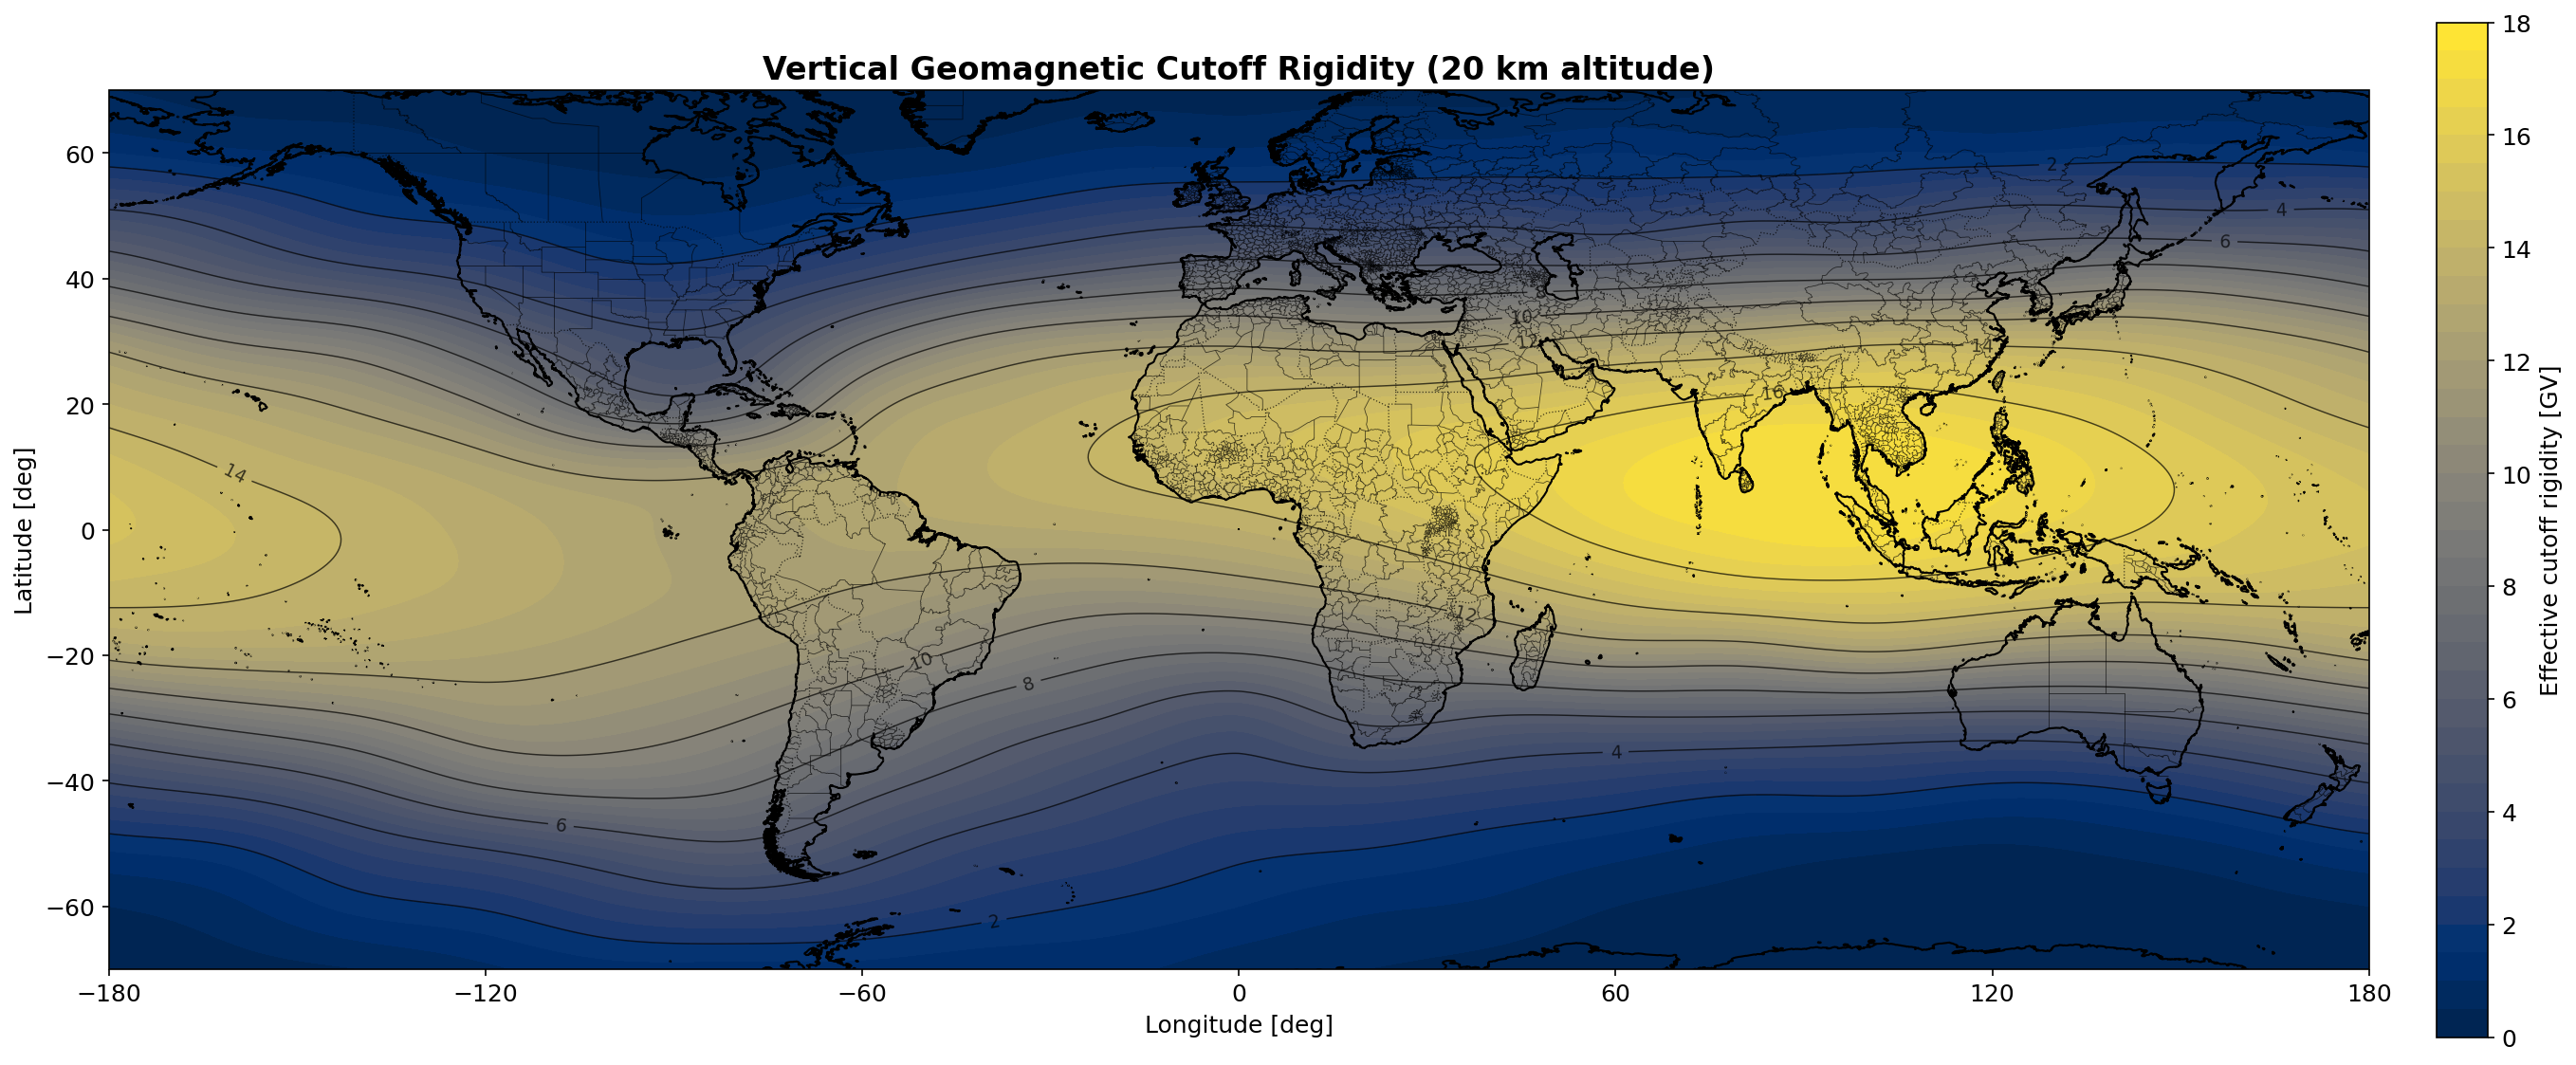

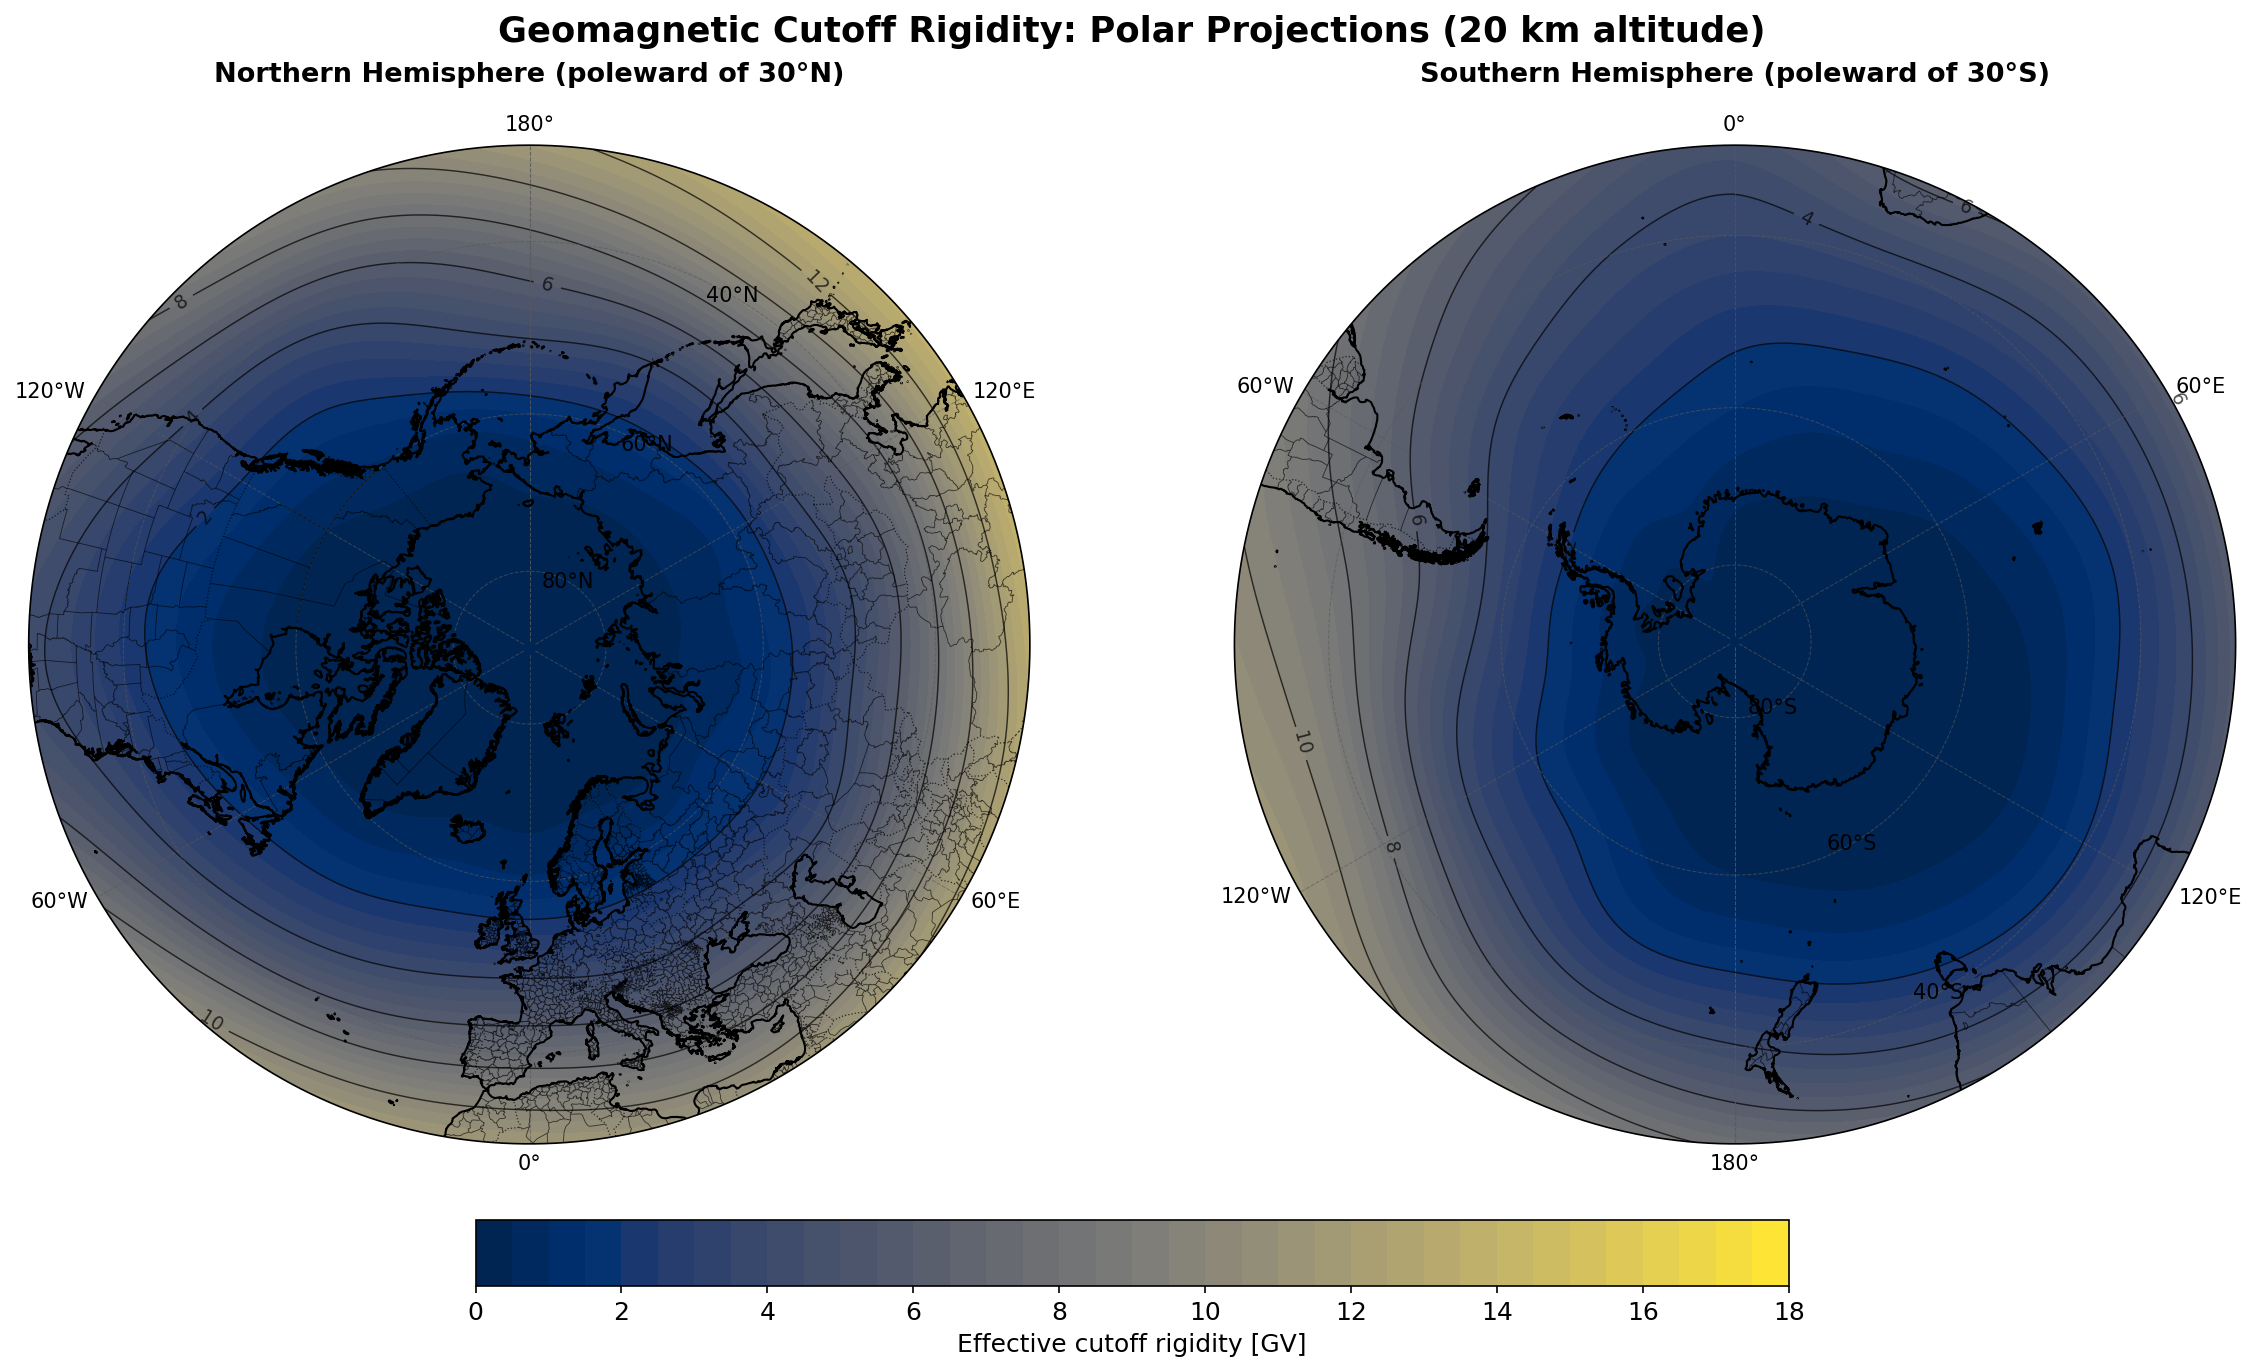

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import RectBivariateSpline, CubicSpline, RegularGridInterpolator

PC = ccrs.PlateCarree()
CMAP = "cividis"
CMAP_LOW = plt.get_cmap(CMAP)(0.0)

ALT = 20
ALT_LABEL = "Sea level (0 km)" if ALT == 0 else f"{ALT:g} km altitude"
TAG = f"{ALT:g}km"

# Base configuration scaled for high-res output
plt.rcParams.update({
    "font.size": 12,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
})

R_FLOOR = 1e-3

# ------------------------------------------------------------------
# Administrative boundaries: states and provinces (scale="10m" for global coverage)
# ------------------------------------------------------------------
STATES_PROVINCES = cfeature.NaturalEarthFeature(
    category="cultural",
    name="admin_1_states_provinces_lines",
    scale="10m",
    facecolor="none"
)

# ------------------------------------------------------------------
# 0. Quick diagnostics on the input data
# ------------------------------------------------------------------
_r = np.asarray(r_grid, float)

print(
    f"r_grid: shape={_r.shape}, min={np.nanmin(_r):.3f}, "
    f"max={np.nanmax(_r):.3f}, NaN={np.isnan(_r).sum()}, "
    f"<=0: {(_r <= 0).sum()}"
)

# ------------------------------------------------------------------
# 1. Data preparation: smooth, periodic, pole-to-pole field
# ------------------------------------------------------------------
def build_smooth_field(
    lon_grid, lat_grid, r_grid, step=0.5, n_wrap=3, n_pole=4
):
    lon = np.asarray(lon_grid, float)
    lat = np.asarray(lat_grid, float)
    r = np.asarray(r_grid, float)

    if np.isnan(r).any():
        raise ValueError(
            "r_grid contains NaN: some grid points were not computed."
        )

    # Latitude south -> north
    if lat[0] > lat[-1]:
        lat, r = lat[::-1], r[::-1]

    # Longitude -> [0, 360), sorted, no duplicated seam column
    lon = np.mod(lon, 360.0)
    order = np.argsort(lon, kind="stable")
    lon, r = lon[order], r[:, order]

    keep = np.concatenate(([True], np.diff(lon) > 1e-9))
    lon, r = lon[keep], r[:, keep]

    # Separate exact-pole rows, if present
    tol = 1e-6
    has_s = lat <= -90 + tol
    has_n = lat >= 90 - tol
    mid = ~(has_s | has_n)

    lat_m, r_m = lat[mid], r[mid]
    k = min(n_pole, len(lat_m))

    # Field at longitude + 180 degrees
    lon_c = np.append(lon, lon[0] + 360.0)

    def shift180(block):
        cs = CubicSpline(
            lon_c,
            np.hstack((block, block[:, :1])),
            axis=1,
            bc_type="periodic"
        )
        return cs(np.mod(lon + 180.0, 360.0))

    # Mirrored rows beyond each pole
    lat_nm = (180.0 - lat_m[-k:])[::-1]
    r_nm = shift180(r_m[-k:])[::-1]

    lat_sm = (-180.0 - lat_m[:k])[::-1]
    r_sm = shift180(r_m[:k])[::-1]

    lat_parts, r_parts = [lat_sm], [r_sm]

    if has_s.any():
        lat_parts.append(np.array([-90.0]))
        r_parts.append(
            np.full((1, lon.size), r[has_s].mean())
        )

    lat_parts.append(lat_m)
    r_parts.append(r_m)

    if has_n.any():
        lat_parts.append(np.array([90.0]))
        r_parts.append(
            np.full((1, lon.size), r[has_n].mean())
        )

    lat_parts.append(lat_nm)
    r_parts.append(r_nm)

    lat_all = np.concatenate(lat_parts)
    r_all = np.vstack(r_parts)

    # Periodic longitude wrapping
    lon_w = np.concatenate((
        lon[-n_wrap:] - 360.0,
        lon,
        lon[:n_wrap] + 360.0
    ))

    r_w = np.hstack((
        r_all[:, -n_wrap:],
        r_all,
        r_all[:, :n_wrap]
    ))

    spline = RectBivariateSpline(
        lat_all, lon_w, r_w, kx=3, ky=3
    )

    lon_f = np.arange(-180, 180 + step / 2, step)
    lat_f = np.arange(-90, 90 + step / 2, step)

    lon_eval = np.mod(lon_f - lon[0], 360.0) + lon[0]

    # Sort longitudes for the spline
    sort_idx = np.argsort(lon_eval)
    lon_eval_sorted = lon_eval[sort_idx]

    r_f_sorted = spline(lat_f, lon_eval_sorted)

    # Restore original longitude ordering
    inv_sort_idx = np.argsort(sort_idx)
    r_f = r_f_sorted[:, inv_sort_idx]

    # Keep interpolated values within the data range
    r_f = np.clip(
        r_f,
        max(r.min(), R_FLOOR),
        r.max()
    )

    return lon_f, lat_f, r_f


lon_f, lat_f, r_f = build_smooth_field(
    lon_grid, lat_grid, r_grid
)

R_MAX = np.ceil(r_f.max())
levels = np.arange(0, R_MAX + 0.5, 0.5)
line_levels = np.arange(2, R_MAX + 1, 2)
cbar_ticks = np.arange(0, R_MAX + 1, 2)

_interp = RegularGridInterpolator(
    (lat_f, lon_f),
    r_f,
    method="linear"
)

# ------------------------------------------------------------------
# 2. Plot helpers
# ------------------------------------------------------------------
def polar_field(north, lat_limit=30, n=900):
    proj = (
        ccrs.NorthPolarStereo()
        if north else ccrs.SouthPolarStereo()
    )

    xb, yb = proj.transform_point(
        0.0,
        lat_limit if north else -lat_limit,
        PC
    )

    R = np.hypot(xb, yb)

    x = np.linspace(-1.02 * R, 1.02 * R, n)
    X, Y = np.meshgrid(x, x)

    pts = PC.transform_points(proj, X, Y)

    lon = np.mod(pts[..., 0] + 180.0, 360.0) - 180.0
    lat = np.clip(pts[..., 1], -90.0, 90.0)

    Z = _interp(
        np.column_stack((lat.ravel(), lon.ravel()))
    ).reshape(X.shape)

    Z = np.ma.masked_where(
        (np.hypot(X, Y) > 1.01 * R) | ~np.isfinite(Z),
        Z
    )

    return X, Y, Z


def draw_field(ax, polar=None):
    if polar is None:
        # Global map
        args, kw = (lon_f, lat_f, r_f), {"transform": PC}
    else:
        # Polar map: native projection coordinates
        args, kw = polar, {}

    cf = ax.contourf(
        *args,
        levels=levels,
        cmap=CMAP,
        extend="neither",
        **kw
    )

    cs = ax.contour(
        *args,
        levels=line_levels,
        colors="black",
        linewidths=0.7,
        alpha=0.7,
        **kw
    )

    ax.clabel(
        cs,
        inline=True,
        inline_spacing=6,
        fontsize=9,
        fmt="%.0f"
    )

    # Coastlines
    ax.coastlines(
        resolution="10m",
        linewidth=1.0,
        color="black",
        zorder=4
    )

    # International borders
    ax.add_feature(
        cfeature.BORDERS,
        linestyle=":",
        linewidth=0.6,
        edgecolor="black",
        alpha=0.7,
        zorder=5
    )

    # Internal state and provincial boundaries
    ax.add_feature(
        STATES_PROVINCES,
        edgecolor="black",
        linewidth=0.4,
        alpha=0.65,
        zorder=5
    )

    return cf


_theta = np.linspace(0, 2 * np.pi, 300)

CIRCLE = mpath.Path(
    np.column_stack([
        np.sin(_theta),
        np.cos(_theta)
    ]) * 0.5 + 0.5
)


def polar_panel(fig, position, hemisphere, lat_limit=30):
    north = hemisphere == "north"

    proj = (
        ccrs.NorthPolarStereo()
        if north else ccrs.SouthPolarStereo()
    )

    ax = fig.add_subplot(position, projection=proj)

    extent = (
        [-180, 180, lat_limit, 90]
        if north
        else [-180, 180, -90, -lat_limit]
    )

    ax.set_extent(extent, crs=PC)
    ax.set_boundary(CIRCLE, transform=ax.transAxes)

    # Fill any unfilled pixels with the lowest colour
    ax.set_facecolor(CMAP_LOW)

    cf = draw_field(
        ax,
        polar=polar_field(north, lat_limit)
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="0.35",
        alpha=0.6,
        linestyle="--",
        xlocs=np.arange(-180, 181, 60),
        ylocs=np.arange(-80, 81, 20)
    )

    gl.rotate_labels = False
    gl.xlabel_style = {"size": 10}
    gl.ylabel_style = {"size": 10}

    name = "Northern" if north else "Southern"

    ax.set_title(
        f"{name} Hemisphere "
        f"(poleward of {lat_limit}°{'N' if north else 'S'})",
        fontsize=13,
        pad=16
    )

    return ax, cf


# ------------------------------------------------------------------
# 3. Figure 1: global map (Enlarged and saved at 600 DPI)
# ------------------------------------------------------------------
fig1 = plt.figure(
    figsize=(18, 9),
    layout="constrained"
)

ax1 = fig1.add_subplot(projection=PC)

ax1.set_extent(
    [-180, 180, -70, 70],
    crs=PC
)

cf1 = draw_field(ax1)

ax1.set_xticks(
    np.arange(-180, 181, 60),
    crs=PC
)

ax1.set_yticks(
    np.arange(-60, 61, 20),
    crs=PC
)

ax1.set_xlabel("Longitude [deg]")
ax1.set_ylabel("Latitude [deg]")

ax1.set_title(
    f"Vertical Geomagnetic Cutoff Rigidity ({ALT_LABEL})",
    fontsize=16
)

cb1 = fig1.colorbar(
    cf1,
    ax=ax1,
    shrink=0.8,
    pad=0.02,
    ticks=cbar_ticks
)

cb1.set_label("Effective cutoff rigidity [GV]")

fig1.savefig(
    f"cutoff_global_{TAG}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------------
# 4. Figure 2: polar projections (Enlarged and saved at 600 DPI)
# ------------------------------------------------------------------
fig2 = plt.figure(
    figsize=(16, 9),
    layout="constrained"
)

fig2.suptitle(
    f"Geomagnetic Cutoff Rigidity: Polar Projections ({ALT_LABEL})",
    fontsize=17,
    fontweight="bold"
)

ax_n, cf_n = polar_panel(
    fig2, 121, "north"
)

ax_s, cf_s = polar_panel(
    fig2, 122, "south"
)

cb2 = fig2.colorbar(
    cf_n,
    ax=[ax_n, ax_s],
    orientation="horizontal",
    location="bottom",
    shrink=0.55,
    pad=0.04,
    ticks=cbar_ticks
)

cb2.set_label("Effective cutoff rigidity [GV]")

fig2.savefig(
    f"cutoff_polar_{TAG}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ------------------------------------------------------------------
# 5. Export Data for Journal Supplementary Material
# ------------------------------------------------------------------

# --- 1. Export Global Grid Data (Figure 1) ---
# Save as a compressed NumPy archive
np.savez(f"global_cutoff_map_data_{TAG}.npz", lon=lon_f, lat=lat_f, rigidity=r_f)

# Save as a flat CSV file (Latitude, Longitude, Rigidity)
LON_mesh, LAT_mesh = np.meshgrid(lon_f, lat_f)
global_csv_data = np.column_stack((LAT_mesh.ravel(), LON_mesh.ravel(), r_f.ravel()))
np.savetxt(
    f"global_cutoff_map_data_{TAG}.csv",
    global_csv_data,
    delimiter=",",
    header="Latitude [deg],Longitude [deg],Effective_Cutoff_Rigidity [GV]",
    comments=""
)


# --- 2. Export Polar Projections Data (Figure 2) ---
# Retrieve the exact stereographic grid data used for the polar plots
X_n, Y_n, Z_n = polar_field(north=True, lat_limit=30)
X_s, Y_s, Z_s = polar_field(north=False, lat_limit=30)

# Save Northern Hemisphere Polar Data
np.savez(f"polar_north_cutoff_map_data_{TAG}.npz", X=X_n, Y=Y_n, rigidity=Z_n)
north_csv_data = np.column_stack((X_n.ravel(), Y_n.ravel(), Z_n.ravel()))
np.savetxt(
    f"polar_north_cutoff_map_data_{TAG}.csv",
    north_csv_data,
    delimiter=",",
    header="Stereographic_X,Stereographic_Y,Effective_Cutoff_Rigidity [GV]",
    comments=""
)

# Save Southern Hemisphere Polar Data
np.savez(f"polar_south_cutoff_data_{TAG}.npz", X=X_s, Y=Y_s, rigidity=Z_s)
south_csv_data = np.column_stack((X_s.ravel(), Y_s.ravel(), Z_s.ravel()))
np.savetxt(
    f"polar_south_cutoff_data_{TAG}.csv",
    south_csv_data,
    delimiter=",",
    header="Stereographic_X,Stereographic_Y,Effective_Cutoff_Rigidity [GV]",
    comments=""
)

print(" All figure datasets successfully exported for journal submission!")

 All figure datasets successfully exported for journal submission!


Elevation data downloaded successfully.


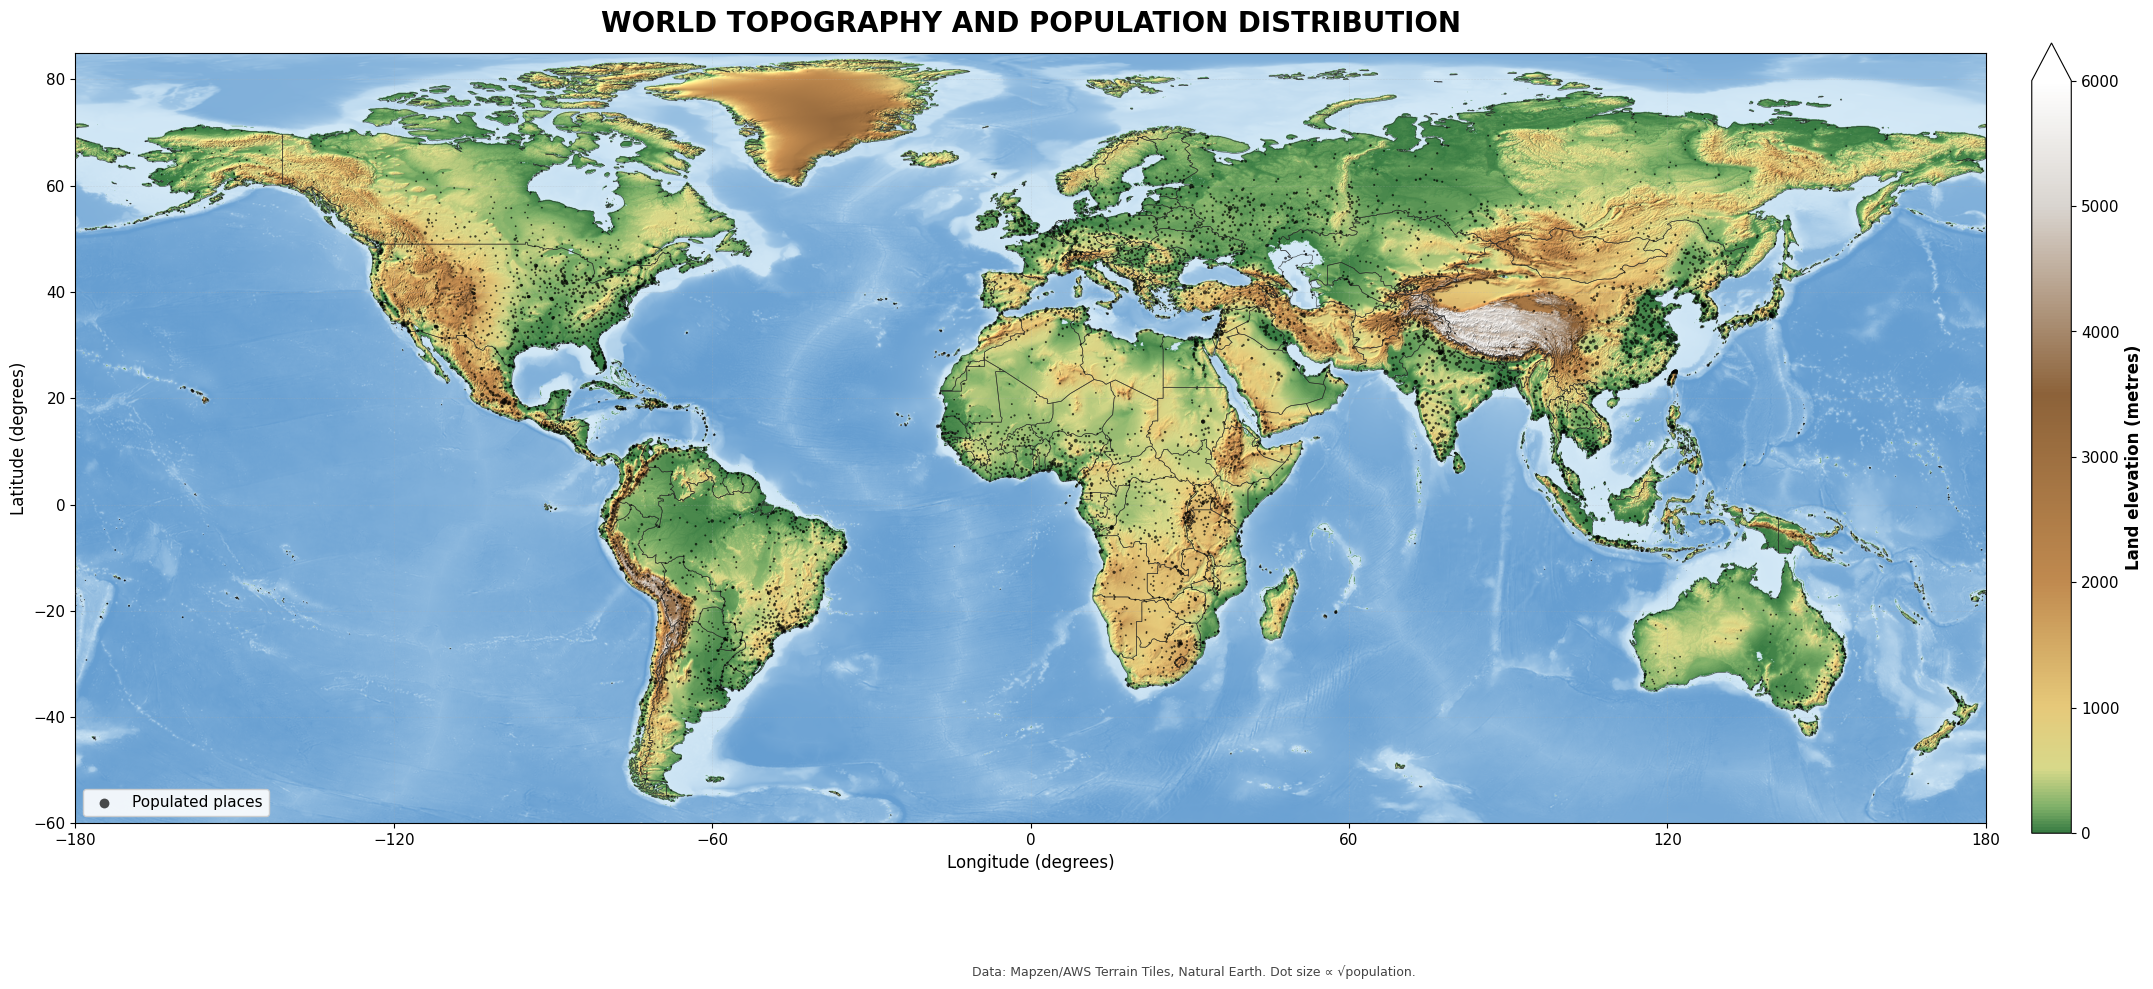

In [ ]:
"""
World topography + country borders + populated places.

Data: Mapzen/AWS Terrain Tiles (Terrarium), Natural Earth (borders, places).
"""
import io
import subprocess
import sys

# ---- install dependencies only if missing (works in Colab and locally) ----
for _mod, _pkg in [("geopandas", "geopandas"), ("matplotlib", "matplotlib"),
                   ("numpy", "numpy"), ("requests", "requests"),
                   ("PIL", "pillow")]:
    try:
        __import__(_mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", _pkg])

from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import time

import numpy as np
import requests
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from PIL import Image

# ============================================================
# SETTINGS
# ============================================================
ZOOM = 4                      # 4 = fast, 5 = sharper (4x more data)
LAT_MIN, LAT_MAX = -60, 85
VMAX = 6000                   # colour-bar maximum (m)
VERT_EXAG = 12                # hillshade exaggeration
SUN_AZ, SUN_ALT = 315, 45     # light direction (degrees)
DPI = 300
OUT_JPG = "world_elevation_population.jpg"
OUT_PNG = "world_elevation_population.png"
CACHE_DIR = Path("tile_cache")

N, TILE = 2 ** ZOOM, 256
SIZE = N * TILE

ELEV_URL = ("https://s3.amazonaws.com/elevation-tiles-prod/"
            "terrarium/{z}/{x}/{y}.png")
BASE = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
COUNTRIES_URL = BASE + "ne_50m_admin_0_countries.geojson"
PLACES_URL = BASE + "ne_10m_populated_places.geojson"

CACHE_DIR.mkdir(exist_ok=True)
session = requests.Session()


# ============================================================
# 1. DOWNLOAD REAL ELEVATION DATA (cached, retried with backoff)
# ============================================================
def fetch(xy):
    x, y = xy
    cache_file = CACHE_DIR / f"{ZOOM}_{x}_{y}.png"
    last_err = None

    for attempt in range(5):
        try:
            if cache_file.exists():
                content = cache_file.read_bytes()
            else:
                r = session.get(ELEV_URL.format(z=ZOOM, x=x, y=y), timeout=60)
                r.raise_for_status()
                content = r.content
                cache_file.write_bytes(content)

            img = np.asarray(Image.open(io.BytesIO(content)).convert("RGB"),
                             dtype=np.float32)
            # Terrarium encoding -> metres
            elev = img[..., 0] * 256 + img[..., 1] + img[..., 2] / 256 - 32768
            return x, y, elev
        except Exception as e:  # noqa: BLE001
            last_err = e
            cache_file.unlink(missing_ok=True)   # drop possibly corrupt cache
            time.sleep(1.5 ** attempt)

    raise RuntimeError(f"Failed to download elevation tile {x}/{y}: {last_err}")


elev_merc = np.empty((SIZE, SIZE), dtype=np.float32)
jobs = [(x, y) for x in range(N) for y in range(N)]

with ThreadPoolExecutor(max_workers=16) as pool:
    for x, y, tile in pool.map(fetch, jobs):
        elev_merc[y * TILE:(y + 1) * TILE, x * TILE:(x + 1) * TILE] = tile

print("Elevation data downloaded successfully.")

# ============================================================
# 2. MERCATOR -> EQUIRECTANGULAR (lat/lon) with bilinear row interpolation
# ============================================================
step = 360.0 / SIZE                                  # degrees per pixel
lats = np.arange(LAT_MAX - step / 2, LAT_MIN, -step)  # pixel centres
phi = np.radians(lats)
yfrac = 0.5 - np.log(np.tan(np.pi / 4 + phi / 2)) / (2 * np.pi)

row_f = np.clip(yfrac * SIZE - 0.5, 0, SIZE - 1)
r0 = np.floor(row_f).astype(int)
r1 = np.minimum(r0 + 1, SIZE - 1)
w = (row_f - r0).astype(np.float32)[:, None]
elev = (1 - w) * elev_merc[r0] + w * elev_merc[r1]
del elev_merc

lat_top, lat_bottom = lats[0] + step / 2, lats[-1] - step / 2  # pixel edges

# ============================================================
# 3. COLOURS + HILLSHADE (latitude-correct) + BATHYMETRY
# ============================================================
stops = [
    (0, "#3a7d44"), (200, "#7fb069"), (500, "#d7d98a"), (1000, "#e6c97a"),
    (2000, "#c08a4f"), (3500, "#8c6239"), (5000, "#d9d4cf"), (6000, "#ffffff"),
]
cmap = LinearSegmentedColormap.from_list("elevation",
                                         [(v / 6000, c) for v, c in stops])
norm = Normalize(0, VMAX)

land = elev > 0
elev_land = np.clip(elev, 0, None)
rgb = cmap(norm(elev_land))[..., :3]

# Pixel size in metres: N-S constant, E-W shrinks with cos(latitude)
dy = step * 111_320.0
dx = np.maximum(dy * np.cos(np.radians(lats)), 1_000.0)[:, None]

dz_dnorth = -np.gradient(elev_land, dy, axis=0)      # rows run north -> south
dz_deast = np.gradient(elev_land, axis=1) / dx

nx, ny = -VERT_EXAG * dz_deast, -VERT_EXAG * dz_dnorth
inv = 1.0 / np.sqrt(nx ** 2 + ny ** 2 + 1.0)
az, alt = np.radians(SUN_AZ), np.radians(SUN_ALT)
lx, ly, lz = np.sin(az) * np.cos(alt), np.cos(az) * np.cos(alt), np.sin(alt)
intensity = (nx * lx + ny * ly + lz) * inv / np.sin(alt)   # flat ground = 1.0
rgb = np.clip(rgb * np.clip(intensity, 0.3, 1.35)[..., None], 0, 1)

# Ocean depth (gamma < 1 emphasises shelves and trenches)
depth = (np.clip(-elev, 0, 6000) / 6000) ** 0.6
shallow = np.array([0.84, 0.92, 0.97])
deep = np.array([0.40, 0.62, 0.82])
rgb[~land] = shallow + (deep - shallow) * depth[~land, None]

# ============================================================
# 4. BORDERS AND POPULATED PLACES
# ============================================================
countries = gpd.read_file(COUNTRIES_URL).to_crs("EPSG:4326")
places = gpd.read_file(PLACES_URL).to_crs("EPSG:4326")
places = places[places.geometry.y.between(LAT_MIN, LAT_MAX)].copy()

# Dot area scales with population (falls back to a constant if column missing)
if "POP_MAX" in places.columns:
    pop = places["POP_MAX"].fillna(0).clip(lower=0).to_numpy(dtype=float)
    dot_size = 1.5 + 22 * np.sqrt(pop / pop.max())
else:
    dot_size = 3

# ============================================================
# 5. PLOT
# ============================================================
lon_span, lat_span = 360, LAT_MAX - LAT_MIN
fig_w = 24
fig, ax = plt.subplots(figsize=(fig_w, fig_w * lat_span / lon_span + 1.2))

ax.imshow(rgb, extent=[-180, 180, lat_bottom, lat_top],
          interpolation="antialiased", aspect="equal", zorder=1)

countries.boundary.plot(ax=ax, color="#292929", linewidth=0.45,
                        alpha=0.8, zorder=3)

ax.scatter(places.geometry.x, places.geometry.y, s=dot_size, c="black",
           alpha=0.7, linewidths=0, zorder=5, label="Populated places")

ax.set_xlim(-180, 180)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xticks(np.arange(-180, 181, 60))
ax.set_yticks(np.arange(-60, 81, 20))
ax.grid(ls="--", lw=0.4, alpha=0.3, zorder=2)
ax.set_xlabel("Longitude (degrees)", fontsize=12)
ax.set_ylabel("Latitude (degrees)", fontsize=12)
ax.set_title("WORLD TOPOGRAPHY AND POPULATION DISTRIBUTION",
             fontsize=20, fontweight="bold", pad=15)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="vertical", pad=0.02,
                    shrink=0.75, extend="max")
cbar.set_label("Land elevation (metres)", fontsize=12, fontweight="bold")

ax.legend(loc="lower left", framealpha=0.9, markerscale=2)
fig.text(0.5, 0.005,
         "Data: Mapzen/AWS Terrain Tiles, Natural Earth. "
         "Dot size ∝ √population.",
         ha="center", fontsize=9, color="#444")
plt.tight_layout()

In [ ]:
import pandas as pd

print("Exporting underlying figure data for journal submission...")

# --- 1. Export Elevation & Bathymetry Grid Data ---
# Generate longitude array corresponding to the pixel columns
lons = np.linspace(-180, 180, SIZE, endpoint=False)

# Save the full equirectangular elevation/bathymetry grid as a compressed archive (.npz)
# (Recommended for raster matrices to keep file sizes manageable)
np.savez_compressed(
    f"world_elevation_bathymetry_zoom{ZOOM}.npz",
    elevation=elev,
    latitudes=lats,
    longitudes=lons
)


# --- 2. Export Country Borders Data ---
# Save country boundaries as a standard GeoJSON file
countries.to_file("world_countries_borders.geojson", driver="GeoJSON")


# --- 3. Export Populated Places Data ---
# Extract coordinates into explicit columns for tabular CSV format
places_csv_data = places.copy()
places_csv_data["longitude"] = places_csv_data.geometry.x
places_csv_data["latitude"] = places_csv_data.geometry.y

# Drop the complex geometry object to make it clean for a standard CSV table
places_table = pd.DataFrame(places_csv_data.drop(columns="geometry", errors="ignore"))
places_table.to_csv("world_populated_places.csv", index=False)

# Also save places as GeoJSON for GIS software compatibility
places.to_file("world_populated_places.geojson", driver="GeoJSON")

print("All topography, country border, and population datasets successfully exported!")

Exporting underlying figure data for journal submission...
✅ All topography, country border, and population datasets successfully exported!


r_grid: shape=(15, 18), min=0.100, max=17.500, NaN=0, <=0: 0


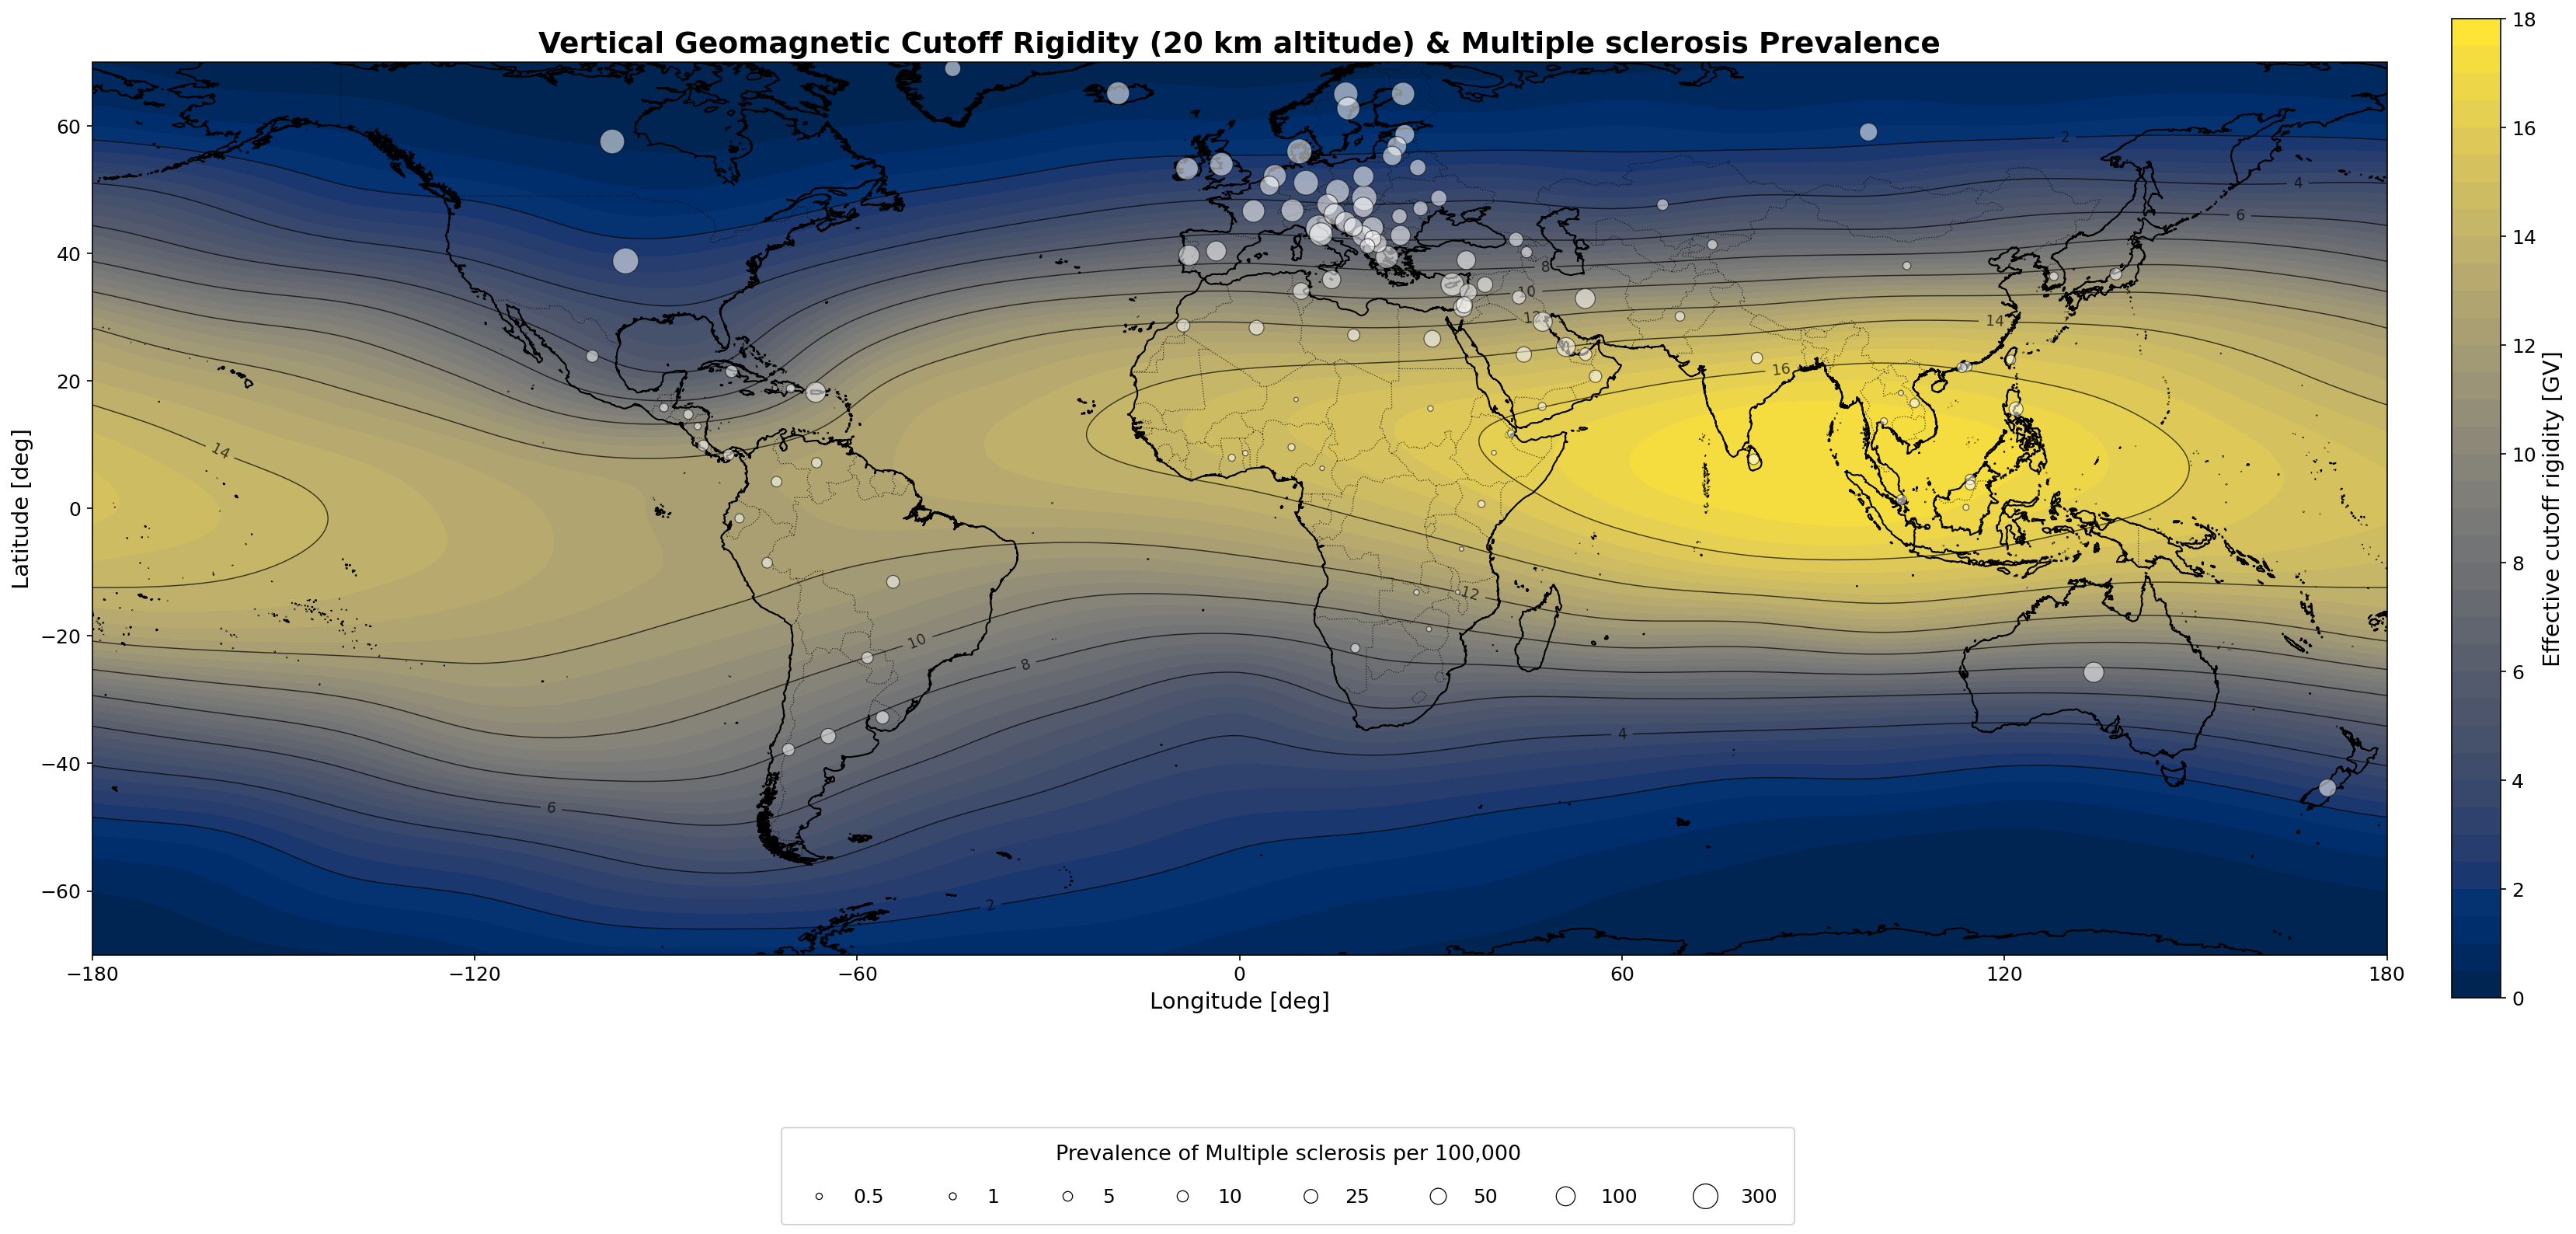

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
from scipy.interpolate import RectBivariateSpline, CubicSpline, RegularGridInterpolator

PC = ccrs.PlateCarree()
CMAP = "cividis"
CMAP_LOW = plt.get_cmap(CMAP)(0.0)

ALT = 20
ALT_LABEL = "Sea level (0 km)" if ALT == 0 else f"{ALT:g} km altitude"
TAG = f"{ALT:g}km"

# Base configuration scaled for high-res output
plt.rcParams.update({
    "font.size": 12,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
})

R_FLOOR = 1e-3

# ------------------------------------------------------------------
# Administrative boundaries: states and provinces (scale="10m")
# ------------------------------------------------------------------
STATES_PROVINCES = cfeature.NaturalEarthFeature(
    category="cultural",
    name="admin_1_states_provinces_lines",
    scale="10m",
    facecolor="none"
)

# ------------------------------------------------------------------
# 0. Quick diagnostics on the input data
# ------------------------------------------------------------------
_r = np.asarray(r_grid, float)

print(
    f"r_grid: shape={_r.shape}, min={np.nanmin(_r):.3f}, "
    f"max={np.nanmax(_r):.3f}, NaN={np.isnan(_r).sum()}, "
    f"<=0: {(_r <= 0).sum()}"
)

# ------------------------------------------------------------------
# 1. Data preparation: smooth, periodic, pole-to-pole field
# ------------------------------------------------------------------
def build_smooth_field(
    lon_grid, lat_grid, r_grid, step=0.5, n_wrap=3, n_pole=4
):
    lon = np.asarray(lon_grid, float)
    lat = np.asarray(lat_grid, float)
    r = np.asarray(r_grid, float)

    if np.isnan(r).any():
        raise ValueError(
            "r_grid contains NaN: some grid points were not computed."
        )

    # Latitude south -> north
    if lat[0] > lat[-1]:
        lat, r = lat[::-1], r[::-1]

    # Longitude -> [0, 360), sorted, no duplicated seam column
    lon = np.mod(lon, 360.0)
    order = np.argsort(lon, kind="stable")
    lon, r = lon[order], r[:, order]

    keep = np.concatenate(([True], np.diff(lon) > 1e-9))
    lon, r = lon[keep], r[:, keep]

    # Separate exact-pole rows, if present
    tol = 1e-6
    has_s = lat <= -90 + tol
    has_n = lat >= 90 - tol
    mid = ~(has_s | has_n)

    lat_m, r_m = lat[mid], r[mid]
    k = min(n_pole, len(lat_m))

    # Field at longitude + 180 degrees
    lon_c = np.append(lon, lon[0] + 360.0)

    def shift180(block):
        cs = CubicSpline(
            lon_c,
            np.hstack((block, block[:, :1])),
            axis=1,
            bc_type="periodic"
        )
        return cs(np.mod(lon + 180.0, 360.0))

    # Mirrored rows beyond each pole
    lat_nm = (180.0 - lat_m[-k:])[::-1]
    r_nm = shift180(r_m[-k:])[::-1]

    lat_sm = (-180.0 - lat_m[:k])[::-1]
    r_sm = shift180(r_m[:k])[::-1]

    lat_parts, r_parts = [lat_sm], [r_sm]

    if has_s.any():
        lat_parts.append(np.array([-90.0]))
        r_parts.append(
            np.full((1, lon.size), r[has_s].mean())
        )

    lat_parts.append(lat_m)
    r_parts.append(r_m)

    if has_n.any():
        lat_parts.append(np.array([90.0]))
        r_parts.append(
            np.full((1, lon.size), r[has_n].mean())
        )

    lat_parts.append(lat_nm)
    r_parts.append(r_nm)

    lat_all = np.concatenate(lat_parts)
    r_all = np.vstack(r_parts)

    # Periodic longitude wrapping
    lon_w = np.concatenate((
        lon[-n_wrap:] - 360.0,
        lon,
        lon[:n_wrap] + 360.0
    ))

    r_w = np.hstack((
        r_all[:, -n_wrap:],
        r_all,
        r_all[:, :n_wrap]
    ))

    spline = RectBivariateSpline(
        lat_all, lon_w, r_w, kx=3, ky=3
    )

    lon_f = np.arange(-180, 180 + step / 2, step)
    lat_f = np.arange(-90, 90 + step / 2, step)

    lon_eval = np.mod(lon_f - lon[0], 360.0) + lon[0]

    # Sort longitudes for the spline
    sort_idx = np.argsort(lon_eval)
    lon_eval_sorted = lon_eval[sort_idx]

    r_f_sorted = spline(lat_f, lon_eval_sorted)

    # Restore original longitude ordering
    inv_sort_idx = np.argsort(sort_idx)
    r_f = r_f_sorted[:, inv_sort_idx]

    # Keep interpolated values within the data range
    r_f = np.clip(
        r_f,
        max(r.min(), R_FLOOR),
        r.max()
    )

    return lon_f, lat_f, r_f


lon_f, lat_f, r_f = build_smooth_field(
    lon_grid, lat_grid, r_grid
)

R_MAX = np.ceil(r_f.max())
levels = np.arange(0, R_MAX + 0.5, 0.5)
line_levels = np.arange(2, R_MAX + 1, 2)
cbar_ticks = np.arange(0, R_MAX + 1, 2)

_interp = RegularGridInterpolator(
    (lat_f, lon_f),
    r_f,
    method="linear"
)

# ------------------------------------------------------------------
# 2. Plot helpers (with toggle for state/provincial boundaries)
# ------------------------------------------------------------------
def draw_field(ax, polar=None, include_states=True):
    if polar is None:
        # Global map
        args, kw = (lon_f, lat_f, r_f), {"transform": PC}
    else:
        # Polar map: native projection coordinates
        args, kw = polar, {}

    cf = ax.contourf(
        *args,
        levels=levels,
        cmap=CMAP,
        extend="neither",
        **kw
    )

    cs = ax.contour(
        *args,
        levels=line_levels,
        colors="black",
        linewidths=0.7,
        alpha=0.7,
        **kw
    )

    ax.clabel(
        cs,
        inline=True,
        inline_spacing=6,
        fontsize=9,
        fmt="%.0f"
    )

    # Coastlines
    ax.coastlines(
        resolution="10m",
        linewidth=1.0,
        color="black",
        zorder=4
    )

    # International borders
    ax.add_feature(
        cfeature.BORDERS,
        linestyle=":",
        linewidth=0.6,
        edgecolor="black",
        alpha=0.7,
        zorder=5
    )

    # Internal state and provincial boundaries (optional)
    if include_states:
        ax.add_feature(
            STATES_PROVINCES,
            edgecolor="black",
            linewidth=0.4,
            alpha=0.65,
            zorder=5
        )

    return cf

# ------------------------------------------------------------------
# 3. Country Data & Figure 3: Country Bubbles Map and MS
# ------------------------------------------------------------------
COUNTRIES = [
    ("San Marino", 377, 12.46, 43.94),
    ("United States of America", 362, -96.33, 38.82),
    ("Slovakia", 312, 19.58, 48.70),
    ("Denmark", 306, 9.38, 56.00),
    ("Germany", 300, 10.43, 51.08),
    ("Canada", 290, -98.42, 57.55),
    ("Norway", 268, 16.67, 64.98),
    ("Czech Republic", 249, 15.38, 49.75),
    ("United Kingdom", 229, -2.85, 53.98),
    ("Italy", 227, 12.76, 42.98),
    ("Finland", 224, 25.66, 65.02),
    ("Cyprus", 217, 33.38, 35.12),
    ("Sweden", 215, 17.06, 62.73),
    ("Iceland", 212, -19.06, 65.12),
    ("Netherlands", 210, 5.55, 52.13),
    ("Switzerland", 207, 8.29, 46.74),
    ("Greece", 198, 23.11, 39.42),
    ("France", 198, 2.19, 46.64),
    ("Ireland", 193, -8.24, 53.30),
    ("Serbia", 176, 20.86, 44.03),
    ("Austria", 153, 13.80, 47.63),
    ("Slovenia", 152, 14.89, 46.14),
    ("Poland", 144, 19.44, 52.07),
    ("Croatia", 144, 16.63, 44.91),
    ("Portugal", 143, -7.93, 39.68),
    ("Montenegro", 135, 19.30, 42.74),
    ("Australia", 131, 134.02, -25.70),
    ("Hungary", 130, 19.40, 47.23),
    ("Puerto Rico", 128, -66.49, 18.22),
    ("Spain", 123, -3.65, 40.37),
    ("Bulgaria", 121, 25.25, 42.82),
    ("Iran, Islamic Republic of", 121, 54.24, 32.91),
    ("Estonia", 113, 25.92, 58.65),
    ("Latvia", 107, 24.69, 56.81),
    ("Kuwait", 105, 47.56, 29.28),
    ("Belgium", 104, 4.68, 50.62),
    ("Lithuania", 104, 23.95, 55.29),
    ("Qatar", 98, 51.20, 25.32),
    ("Turkey", 96, 35.57, 38.93),
    ("Israel", 95, 35.03, 31.51),
    ("Bosnia and Herzegovina", 91, 17.83, 44.14),
    ("Malta", 87, 14.44, 35.89),
    ("North Macedonia", 82, 21.71, 41.59),
    ("Russian Federation", 79, 98.67, 59.04),
    ("New Zealand", 72, 170.69, -43.83),
    ("Lebanon", 63, 35.90, 33.91),
    ("Egypt", 59, 30.24, 26.61),
    ("Tunisia", 58, 9.66, 34.09),
    ("Palestinian Authority", 53, 35.24, 31.93),
    ("Kosovo", 53, 20.90, 42.30),
    ("Belarus", 50, 27.96, 53.47),
    ("Greenland", 48, -45.00, 69.00),
    ("Ukraine", 48, 31.27, 48.66),
    ("Syrian Arab Republic", 43, 38.51, 35.10),
    ("Saudi Arabia", 41, 44.60, 24.14),
    ("Argentina", 38, -64.53, -35.70),
    ("Romania", 37, 25.09, 45.82),
    ("Algeria", 35, 2.66, 28.35),
    ("Albania", 34, 20.06, 41.14),
    ("Moldova, Republic of", 34, 28.39, 47.07),
    ("Georgia", 30, 43.38, 42.18),
    ("Philippines", 29, 121.82, 15.59),
    ("Iraq", 23, 43.83, 33.11),
    ("Uruguay", 21, -56.02, -32.78),
    ("Morocco", 20, -8.82, 28.69),
    ("Brazil", 19, -54.36, -11.52),
    ("United Arab Emirates", 18, 54.28, 24.18),
    ("Chile", 16, -70.77, -37.83),
    ("Oman", 16, 55.84, 20.72),
    ("Libya", 15, 17.91, 27.20),
    ("Mexico", 15, -101.55, 23.87),
    ("Cuba", 15, -79.70, 21.48),
    ("Japan", 14, 137.47, 36.77),
    ("Paraguay", 12, -58.39, -23.42),
    ("India", 11, 81.17, 23.59),
    ("Kazakhstan", 11, 66.38, 47.64),
    ("Armenia", 10, 45.05, 40.18),
    ("Costa Rica", 9, -84.15, 9.86),
    ("Panama", 9, -80.14, 8.44),
    ("Sri Lanka", 8, 80.67, 7.70),
    ("Peru", 8, -74.11, -8.52),
    ("Colombia", 8, -72.64, 4.19),
    ("Venezuela", 7, -66.36, 7.15),
    ("Singapore", 7, 103.81, 1.35),
    ("Brunei Darussalam", 7, 114.64, 4.54),
    ("Hong Kong", 7, 114.09, 22.22),
    ("Macao SAR", 6, 113.33, 22.09),
    ("Malaysia", 6, 114.63, 3.67),
    ("Kyrgyzstan", 6, 74.18, 41.36),
    ("Pakistan", 5, 69.09, 30.12),
    ("Honduras", 5, -86.49, 14.74),
    ("Taiwan", 5, 121.01, 23.33),
    ("Vietnam", 4, 105.91, 16.52),
    ("Ecuador", 4, -78.46, -1.56),
    ("Namibia", 4, 18.16, -21.91),
    ("Guatemala", 3, -90.31, 15.82),
    ("Korea, Republic of", 3, 127.76, 36.40),
    ("Dominican Republic", 3, -70.43, 18.78),
    ("China", 2, 104.69, 38.07),
    ("Yemen", 2, 47.47, 16.00),
    ("Nicaragua", 1, -85.02, 12.89),
    ("Djibouti", 1, 42.61, 11.75),
    ("Nigeria", 1, 8.15, 9.61),
    ("Thailand", 1, 101.09, 13.66),
    ("Kenya", 1, 37.95, 0.69),
    ("Ghana", 1, -1.22, 7.95),
    ("Indonesia", 0.3, 113.97, 0.16),
    ("Togo", 0.2, 0.90, 8.66),
    ("Sudan", 0.2, 29.95, 15.67),
    ("Zambia", 0.2, 27.76, -13.16),
    ("Lao, People's Democratic Republic of", 0.1, 103.76, 18.12),
    ("Zimbabwe", 0.1, 29.72, -18.93),
    ("Haiti", 0.1, -72.89, 18.88),
    ("Ethiopia", 0.04, 39.91, 8.73),
    ("Cameroon", 0.02, 12.95, 6.29),
    ("Malawi", 0.02, 34.23, -13.13),
    ("Niger", 0.01, 8.87, 17.08),
    ("Tanzania, United Republic of", 0.01, 34.82, -6.36),
]

names = [c[0] for c in COUNTRIES]
vals = np.array([c[1] for c in COUNTRIES], float)
lons = np.array([c[2] for c in COUNTRIES], float)
lats = np.array([c[3] for c in COUNTRIES], float)

S_MIN, S_MAX, GAMMA = 6, 260, 0.5

def size_of(v):
    return S_MIN + (S_MAX - S_MIN) * (np.asarray(v, float) / vals.max()) ** GAMMA

LEGEND_VALUES = [0.5, 1, 5, 10, 25, 50, 100, 300]
LEGEND_TITLE = "Prevalence of Multiple sclerosis per 100,000"

fig3 = plt.figure(figsize=(22, 11.5), layout="constrained")
ax3 = fig3.add_subplot(projection=PC)
ax3.set_extent([-180, 180, -70, 70], crs=PC)

# Call draw_field with include_states=False so only country borders are shown
cf3 = draw_field(ax3, include_states=False)

order = np.argsort(-vals)
ax3.scatter(lons[order], lats[order], s=size_of(vals[order]),
            facecolor="white", edgecolor="black", linewidth=0.6, alpha=0.55,
            transform=PC, zorder=5)

ax3.set_xticks(np.arange(-180, 181, 60), crs=PC)
ax3.set_yticks(np.arange(-60, 61, 20), crs=PC)
ax3.set_xlabel("Longitude [deg]", fontsize=14)
ax3.set_ylabel("Latitude [deg]", fontsize=14)
ax3.tick_params(labelsize=12)
ax3.set_title(f"Vertical Geomagnetic Cutoff Rigidity ({ALT_LABEL}) & Multiple sclerosis Prevalence", fontsize=18)

cb3 = fig3.colorbar(cf3, ax=ax3, shrink=0.8, pad=0.02, ticks=cbar_ticks)
cb3.set_label("Effective cutoff rigidity [GV]", fontsize=14)
cb3.ax.tick_params(labelsize=12)

handles = [
    Line2D([], [], linestyle="none", marker="o",
           markersize=np.sqrt(size_of(v)),
           markerfacecolor=(1, 1, 1, 0.55), markeredgecolor="black", markeredgewidth=0.6)
    for v in LEGEND_VALUES
]
fig3.legend(handles, [f"{v:g}" for v in LEGEND_VALUES],
            title=LEGEND_TITLE, title_fontsize=13, fontsize=12,
            loc="outside lower center", ncol=len(LEGEND_VALUES),
            frameon=True, labelspacing=1.2, handletextpad=0.8, columnspacing=2.5, borderpad=0.9)

fig3.savefig(f"cutoff_global_{TAG}_countries.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Export Data
# ============================================================
import pandas as pd

print("Exporting Figure 3 country-level data for journal submission...")

# Build a structured dataset from the COUNTRIES list
countries_export_list = []
for name, val, lon, lat in COUNTRIES:
    marker_area = float(size_of(val))
    countries_export_list.append({
        "Country_Name": name,
        "Value": val,
        "Longitude_deg": lon,
        "Latitude_deg": lat,
        "Marker_Area_pt2": marker_area
    })

df_countries = pd.DataFrame(countries_export_list)

# 1. Save as a standard tabular CSV file
csv_filename = f"country_cutoff_MS_{TAG}.csv"
df_countries.to_csv(csv_filename, index=False)

# 2. Save as a JSON file for structured metadata archives
json_filename = f"country_cutoff_MS_{TAG}.json"
df_countries.to_json(json_filename, orient="records", indent=4)

print(f" Figure 3 data successfully exported to '{csv_filename}' and '{json_filename}'!")

Exporting Figure 3 country-level data for journal submission...
 Figure 3 data successfully exported to 'country_cutoff_MS_20km.csv' and 'country_cutoff_MS_20km.json'!


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_populated_places_simple.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Supplementary table saved to country_rigidity_stats22_20km.csv
n = 118 countries (population-weighted)
Spearman  Prevalence of Multiple sclerosis per 100,000 vs rigidity:            rho = -0.75, p = 8.8e-23
Spearman  Prevalence of Multiple sclerosis per 100,000vs |latitude|:          rho = +0.80, p = 4.4e-27
Partial   Prevalence of Multiple sclerosis per 100,000 vs rigidity | |lat|:    rho = -0.11, p = 0.22


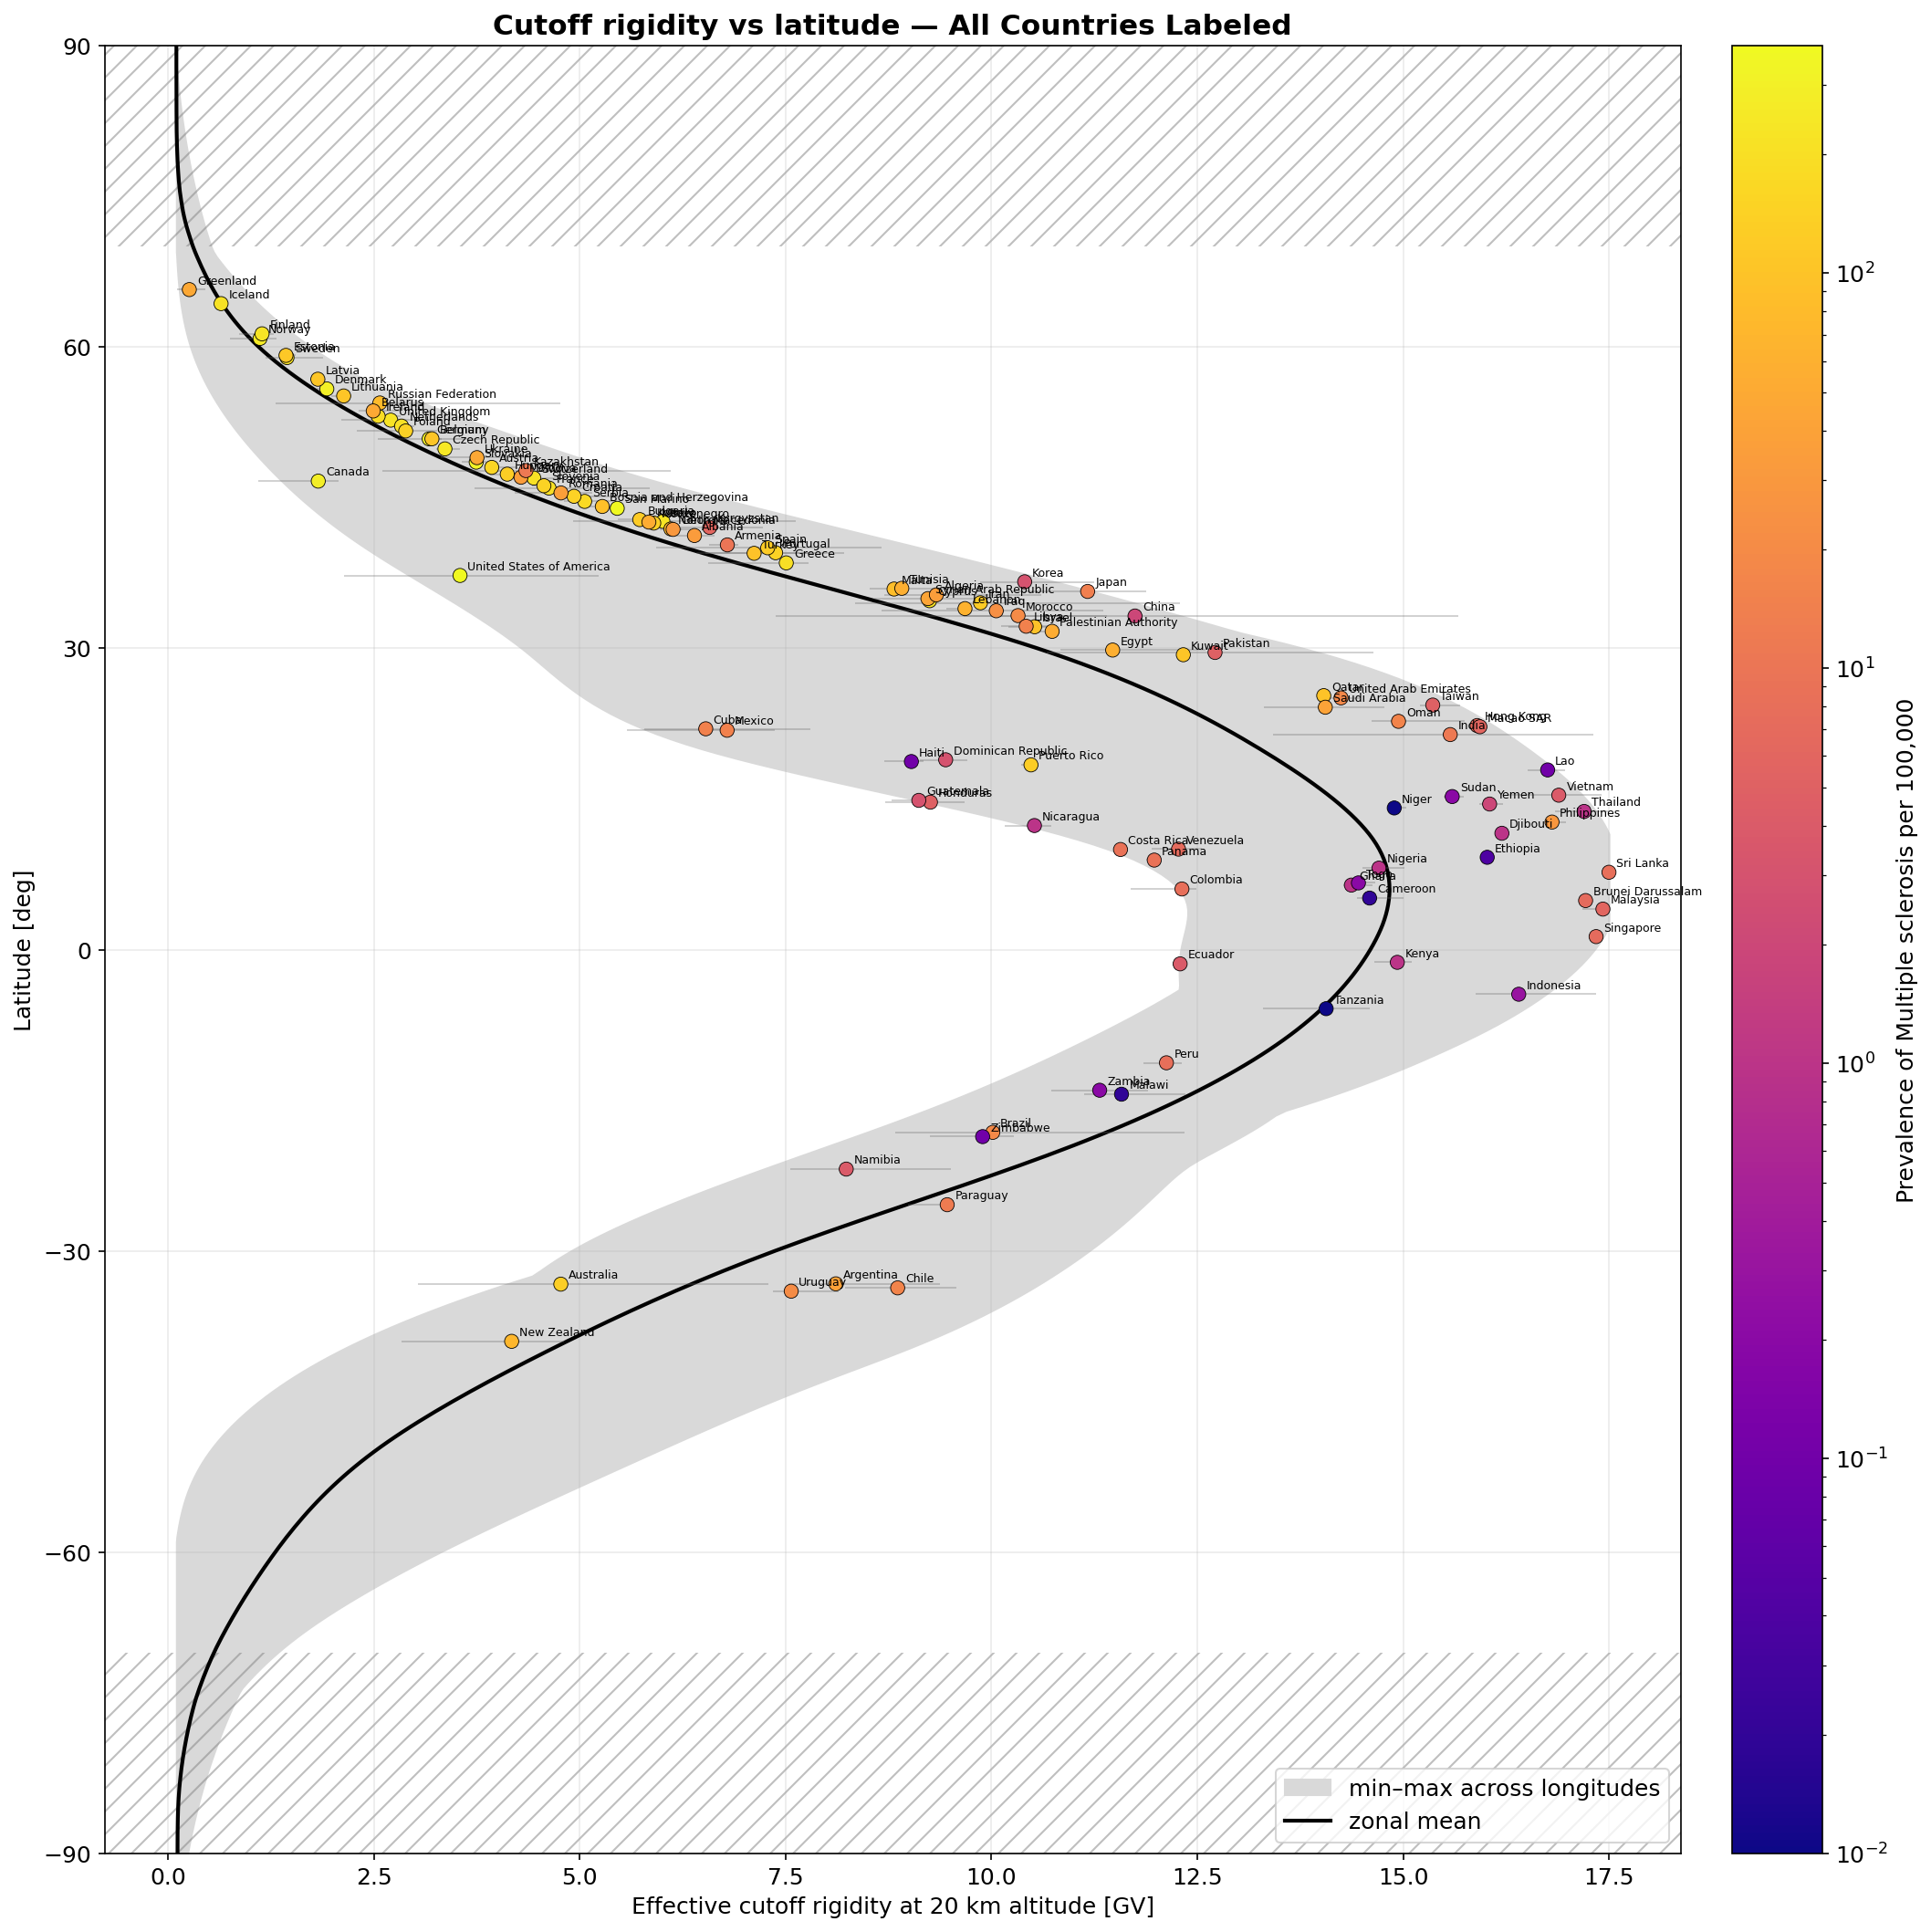

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.io.shapereader as shpreader
import shapely
from scipy.interpolate import RegularGridInterpolator
from scipy import stats
from matplotlib.colors import LogNorm

VALUE_LABEL = "Prevalence of Multiple sclerosis per 100,000"        # edit to the full name of your quantity
WEIGHTING = "population"              # "population" (city-population proxy) or "area" (cos-lat weighted)
MIN_VALUE = 0.0                       # exclude countries with value below this from the statistics (e.g. 0.1)

# ------------------------------------------------------------------
# 1. Natural Earth geometries and name matching
# ------------------------------------------------------------------
ALIASES = {
    "Czech Republic": ["Czechia"], "Iran, Islamic Republic of": ["Iran"],
    "Russian Federation": ["Russia"], "Korea, Republic of": ["South Korea"],
    "Moldova, Republic of": ["Moldova"], "Lao, People's Democratic Republic of": ["Laos"],
    "Tanzania, United Republic of": ["United Republic of Tanzania", "Tanzania"],
    "Palestinian Authority": ["Palestine"], "Brunei Darussalam": ["Brunei"],
    "Hong Kong": ["Hong Kong S.A.R.", "Hong Kong SAR"],
    "Macao SAR": ["Macao S.A.R", "Macao", "Macau"],
    "Syrian Arab Republic": ["Syria"], "Vietnam": ["Viet Nam"],
    "Turkey": ["Turkiye", "Türkiye"], "USA": ["United States"],
    "North Macedonia": ["Macedonia"], "Sudan": ["Sudan"],
}
norm = lambda s: "".join(ch for ch in str(s).lower() if ch.isalnum() or ch == " ").strip()

shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
GEOMS = {}
for rec in shpreader.Reader(shp).records():
    for f in ("NAME", "NAME_LONG", "ADMIN", "FORMAL_EN", "NAME_EN"):
        v = rec.attributes.get(f)
        if v:
            GEOMS.setdefault(norm(v), rec.geometry)

def find_geom(name):
    for cand in [name] + ALIASES.get(name, []):
        g = GEOMS.get(norm(cand))
        if g is not None:
            return g
    return None

# City points (population proxy for weighting)
shp_pp = shpreader.natural_earth(resolution="10m", category="cultural", name="populated_places_simple")
cx, cy, cp = [], [], []
for rec in shpreader.Reader(shp_pp).records():
    pop = rec.attributes.get("pop_max") or rec.attributes.get("POP_MAX") or 0
    if pop and pop > 0:
        cx.append(rec.geometry.x); cy.append(rec.geometry.y); cp.append(float(pop))
cx, cy, cp = map(np.array, (cx, cy, cp))

# ------------------------------------------------------------------
# 2. Sampling the smoothed cutoff field inside each country
# ------------------------------------------------------------------
interp = RegularGridInterpolator((lat_f, lon_f), r_f, bounds_error=False, fill_value=None)
LONm, LATm = np.meshgrid(lon_f, lat_f)
gx, gy, gr = LONm.ravel(), LATm.ravel(), r_f.ravel()

def inside(geom, x, y):
    x0, y0, x1, y1 = geom.bounds
    pre = np.flatnonzero((x >= x0) & (x <= x1) & (y >= y0) & (y <= y1))
    if pre.size == 0:
        return pre
    shapely.prepare(geom)
    return pre[shapely.contains_xy(geom, x[pre], y[pre])]

def wquantile(x, w, q):
    i = np.argsort(x); x, w = x[i], w[i]
    c = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, c, x)

def wmean(x, w):
    return np.sum(x * w) / np.sum(w)

rows, unmatched = [], []
for name, val, lon0, lat0 in COUNTRIES:
    geom = find_geom(name)
    # --- area sample ---
    if geom is not None:
        sel = inside(geom, gx, gy)
    else:
        sel = np.array([], int); unmatched.append(name)
    if sel.size:
        a_r, a_lat, a_lon, a_w = gr[sel], gy[sel], gx[sel], np.cos(np.deg2rad(gy[sel]))
    else:                                       # tiny / unmatched: single point
        p = geom.representative_point() if geom is not None else None
        plon, plat = (p.x, p.y) if p is not None else (lon0, lat0)
        a_r, a_lat, a_lon, a_w = (np.array([float(interp([[plat, plon]])[0])]),
                                np.array([plat]), np.array([plon]), np.array([1.0]))
    # --- population sample (cities inside the country) ---
    sel_c = inside(geom, cx, cy) if geom is not None else np.array([], int)
    if WEIGHTING == "population" and sel_c.size:
        r_s = interp(np.column_stack([cy[sel_c], cx[sel_c]]))
        lat_s, w_s = cy[sel_c], cp[sel_c]
    else:
        r_s, lat_s, w_s = a_r, a_lat, a_w
    rows.append(dict(
        country=name, val=val,
        rig=wmean(r_s, w_s), p10=wquantile(r_s, w_s, 0.10), p90=wquantile(r_s, w_s, 0.90),
        lat=wmean(lat_s, w_s), abs_lat=wmean(np.abs(lat_s), w_s),
        rig_area=wmean(a_r, a_w), n_cells=int(sel.size), n_cities=int(sel_c.size),
    ))

df = pd.DataFrame(rows)
if unmatched:
    print("No polygon match (single-point fallback used):", unmatched)

# Save the comprehensive table for all countries as a supplementary file
supplementary_filename = f"country_rigidity_stats22_{TAG}.csv"
df.to_csv(supplementary_filename, index=False)
print(f"Supplementary table saved to {supplementary_filename}")

# ------------------------------------------------------------------
# 3. Correlations (rank-based: values are heavily skewed)
# ------------------------------------------------------------------
def partial_spearman(x, y, z):
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    r = stats.pearsonr(ex, ey)[0]
    dof = len(x) - 3
    t = r * np.sqrt(dof / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), dof)

d = df[df.val >= MIN_VALUE]
rho, p = stats.spearmanr(d.rig, d.val)
rho_lat, p_lat = stats.spearmanr(d.abs_lat, d.val)
prho, pp = partial_spearman(d.rig, d.val, d.abs_lat)
print(f"n = {len(d)} countries ({WEIGHTING}-weighted)")
print(f"Spearman  Prevalence of Multiple sclerosis per 100,000 vs rigidity:            rho = {rho:+.2f}, p = {p:.2g}")
print(f"Spearman  Prevalence of Multiple sclerosis per 100,000vs |latitude|:          rho = {rho_lat:+.2f}, p = {p_lat:.2g}")
print(f"Partial   Prevalence of Multiple sclerosis per 100,000 vs rigidity | |lat|:    rho = {prho:+.2f}, p = {pp:.2g}")

# ------------------------------------------------------------------
# 4. Figure B: Big bowl plot listing ALL countries
# ------------------------------------------------------------------
figB, axB = plt.subplots(figsize=(14, 14), layout="constrained")
axB.fill_betweenx(lat_f, r_f.min(axis=1), r_f.max(axis=1), color="0.85",
                  label="min–max across longitudes")
axB.plot(r_f.mean(axis=1), lat_f, "k", lw=2, label="zonal mean")
for lo, hi in ((70, 90), (-90, -70)):                        # outside the simulated grid
    axB.axhspan(lo, hi, facecolor="none", edgecolor="0.5", hatch="//", lw=0, alpha=0.5)
axB.hlines(d.lat, d.p10, d.p90, color="0.4", alpha=0.35, lw=0.8, zorder=2)

scB = axB.scatter(d.rig, d.lat, c=d.val, cmap="plasma",
                  norm=LogNorm(vmin=max(d.val.min(), 0.01), vmax=d.val.max()),
                  s=55, edgecolor="black", linewidth=0.4, zorder=3)

axB.set_ylim(-90, 90)
axB.set_yticks(np.arange(-90, 91, 30))
axB.set_xlabel(f"Effective cutoff rigidity at {ALT_LABEL} [GV]", fontsize=12)
axB.set_ylabel("Latitude [deg]", fontsize=12)
axB.set_title("Cutoff rigidity vs latitude — All Countries Labeled", fontsize=15)
axB.grid(alpha=0.25)
axB.legend(loc="lower right")

cbB = figB.colorbar(scB, ax=axB, pad=0.02)
cbB.set_label(VALUE_LABEL)

# --- Annotate EVERY country on the big figure ---
for _, r in d.iterrows():
    axB.annotate(r.country.split(",")[0], (r.rig, r.lat), xytext=(4, 3),
                 textcoords="offset points", fontsize=6)

figB.savefig(f"cutoff_bowl_all_countries_{TAG}.png", dpi=300, bbox_inches="tight")
plt.show()
files.download(f"country_rigidity_stats22_{TAG}.csv")

In [ ]:
import numpy as np
import pandas as pd
import cartopy.io.shapereader as shpreader
import shapely
from scipy.interpolate import RegularGridInterpolator
from scipy import stats
import plotly.graph_objects as go
import os

VALUE_LABEL = "Prevalence of Multiple sclerosis per 100,000"
WEIGHTING = "population"
MIN_VALUE = 0.0

ALIASES = {
    "Czech Republic": ["Czechia"], "Iran, Islamic Republic of": ["Iran"],
    "Russian Federation": ["Russia"], "Korea, Republic of": ["South Korea"],
    "Moldova, Republic of": ["Moldova"], "Lao, People's Democratic Republic of": ["Laos"],
    "Tanzania, United Republic of": ["United Republic of Tanzania", "Tanzania"],
    "Palestinian Authority": ["Palestine"], "Brunei Darussalam": ["Brunei"],
    "Hong Kong": ["Hong Kong S.A.R.", "Hong Kong SAR"],
    "Macao SAR": ["Macao S.A.R", "Macao", "Macau"],
    "Syrian Arab Republic": ["Syria"], "Vietnam": ["Viet Nam"],
    "Turkey": ["Turkiye", "Türkiye"], "USA": ["United States"],
    "North Macedonia": ["Macedonia"], "Sudan": ["Sudan"],
}
norm = lambda s: "".join(ch for ch in str(s).lower() if ch.isalnum() or ch == " ").strip()

shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
GEOMS = {}
for rec in shpreader.Reader(shp).records():
    for f in ("NAME", "NAME_LONG", "ADMIN", "FORMAL_EN", "NAME_EN"):
        v = rec.attributes.get(f)
        if v:
            GEOMS.setdefault(norm(v), rec.geometry)

def find_geom(name):
    for cand in [name] + ALIASES.get(name, []):
        g = GEOMS.get(norm(cand))
        if g is not None:
            return g
    return None

shp_pp = shpreader.natural_earth(resolution="10m", category="cultural", name="populated_places_simple")
cx, cy, cp = [], [], []
for rec in shpreader.Reader(shp_pp).records():
    pop = rec.attributes.get("pop_max") or rec.attributes.get("POP_MAX") or 0
    if pop and pop > 0:
        cx.append(rec.geometry.x); cy.append(rec.geometry.y); cp.append(float(pop))
cx, cy, cp = map(np.array, (cx, cy, cp))

interp = RegularGridInterpolator((lat_f, lon_f), r_f, bounds_error=False, fill_value=None)
LONm, LATm = np.meshgrid(lon_f, lat_f)
gx, gy, gr = LONm.ravel(), LATm.ravel(), r_f.ravel()

def inside(geom, x, y):
    x0, y0, x1, y1 = geom.bounds
    pre = np.flatnonzero((x >= x0) & (x <= x1) & (y >= y0) & (y <= y1))
    if pre.size == 0:
        return pre
    shapely.prepare(geom)
    return pre[shapely.contains_xy(geom, x[pre], y[pre])]

def wquantile(x, w, q):
    i = np.argsort(x); x, w = x[i], w[i]
    c = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, c, x)

def wmean(x, w):
    return np.sum(x * w) / np.sum(w)

rows = []
for name, val, lon0, lat0 in COUNTRIES:
    geom = find_geom(name)
    if geom is not None:
        sel = inside(geom, gx, gy)
    else:
        sel = np.array([], int)
    if sel.size:
        a_r, a_lat, a_lon, a_w = gr[sel], gy[sel], gx[sel], np.cos(np.deg2rad(gy[sel]))
    else:
        p = geom.representative_point() if geom is not None else None
        plon, plat = (p.x, p.y) if p is not None else (lon0, lat0)
        a_r, a_lat, a_lon, a_w = (np.array([float(interp([[plat, plon]])[0])]),
                                np.array([plat]), np.array([plon]), np.array([1.0]))
    sel_c = inside(geom, cx, cy) if geom is not None else np.array([], int)
    if WEIGHTING == "population" and sel_c.size:
        r_s = interp(np.column_stack([cy[sel_c], cx[sel_c]]))
        lat_s, w_s = cy[sel_c], cp[sel_c]
    else:
        r_s, lat_s, w_s = a_r, a_lat, a_w
    rows.append(dict(
        country=name, val=val,
        rig=wmean(r_s, w_s), p10=wquantile(r_s, w_s, 0.10), p90=wquantile(r_s, w_s, 0.90),
        lat=wmean(lat_s, w_s), abs_lat=wmean(np.abs(lat_s), w_s),
        rig_area=wmean(a_r, a_w), n_cells=int(sel.size), n_cities=int(sel_c.size),
    ))

df = pd.DataFrame(rows)
supplementary_filename = f"country_rigidity_stats_{TAG}.csv"
df.to_csv(supplementary_filename, index=False)
print(f"Supplementary table saved to {supplementary_filename}")

def partial_spearman(x, y, z):
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    r = stats.pearsonr(ex, ey)[0]
    dof = len(x) - 3
    t = r * np.sqrt(dof / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), dof)

d = df[df.val >= MIN_VALUE].copy()
rho, p = stats.spearmanr(d.rig, d.val)
rho_lat, p_lat = stats.spearmanr(d.abs_lat, d.val)
prho, pp = partial_spearman(d.rig, d.val, d.abs_lat)
print(f"n = {len(d)} countries ({WEIGHTING}-weighted)")
print(f"Spearman  Prevalence of Multiple sclerosis per 100,000 vs rigidity:            rho = {rho:+.2f}, p = {p:.2g}")
print(f"Spearman  Prevalence of Multiple sclerosis per 100,000 vs |latitude|:          rho = {rho_lat:+.2f}, p = {p_lat:.2g}")
print(f"Partial   Prevalence of Multiple sclerosis per 100,000 vs rigidity | |lat|:    rho = {prho:+.2f}, p = {pp:.2g}")

# --- Create Logarithmic Color scale mapping manually to bypass Coloraxis type='log' limitation ---
# Replace zeros/negative values with a very small positive number for safe log calculation
val_safe = np.clip(d.val.values, 0.01, None)
log_val = np.log10(val_safe)

fig = go.Figure()

# Background envelope of grid rigidity range
fig.add_trace(go.Scatter(
    x=r_f.min(axis=1), y=lat_f, mode="lines",
    line=dict(width=0), showlegend=False, hoverinfo="skip"
))
fig.add_trace(go.Scatter(
    x=r_f.max(axis=1), y=lat_f, mode="lines",
    fill="tonexty", fillcolor="rgba(200, 200, 200, 0.35)",
    line=dict(width=0), name="min–max across longitudes", hoverinfo="skip"
))

# Zonal mean cutoff rigidity
fig.add_trace(go.Scatter(
    x=r_f.mean(axis=1), y=lat_f, mode="lines",
    name="zonal mean", line=dict(color="black", width=2)
))

# Country markers mapped with the manual log color scheme
country_names = [c.split(",")[0] for c in d.country]
fig.add_trace(go.Scatter(
    x=d.rig,
    y=d.lat,
    mode="markers+text",
    text=country_names,
    textposition="top right",
    textfont=dict(size=9),
    customdata=d.val, # Keep true non-log value for the hovertemplate
    marker=dict(
        size=9,
        color=log_val,
        colorscale="Plasma",
        showscale=True,
        colorbar=dict(
            title=dict(text=VALUE_LABEL, side="right"),
            tickvals=[np.log10(v) for v in [0.01, 0.1, 1, 10, 100, 300] if v <= d.val.max()],
            ticktext=[f"{v}" for v in [0.01, 0.1, 1, 10, 100, 300] if v <= d.val.max()]
        ),
        line=dict(width=0.5, color="black")
    ),
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Rigidity: %{x:.2f} GV<br>"
        "Latitude: %{y:.2f}°<br>"
        "Value (DA per 100k): %{customdata:.2f}<br>"
        "<extra></extra>"
    ),
    name="Countries"
))

fig.update_layout(
    title="Cutoff Rigidity vs Latitude — All Countries Labeled (Interactive & Log-Color)",
    xaxis_title=f"Effective cutoff rigidity at {ALT_LABEL} [GV]",
    yaxis_title="Latitude [deg]",
    yaxis=dict(range=[-90, 90], tickmode="array", tickvals=np.arange(-90, 91, 30)),
    template="plotly_white",
    width=950,
    height=950,
    hovermode="closest"
)

interactive_filename = f"interactive_cutoff_bowl_{TAG}.html"
fig.write_html(interactive_filename)
print(f"Interactive figure successfully saved to: {os.path.abspath(interactive_filename)}")
fig.show()

Supplementary table saved to country_rigidity_stats_20km.csv
n = 118 countries (population-weighted)
Spearman  Prevalence of Multiple sclerosis per 100,000 vs rigidity:            rho = -0.75, p = 8.8e-23
Spearman  Prevalence of Multiple sclerosis per 100,000 vs |latitude|:          rho = +0.80, p = 4.4e-27
Partial   Prevalence of Multiple sclerosis per 100,000 vs rigidity | |lat|:    rho = -0.11, p = 0.22
Interactive figure successfully saved to: /content/interactive_cutoff_bowl_20km.html
